# 2.03. Кластерные A/B-тесты

**План занятия**

1. Зачем назначать воздействие группам: три сценария и выбор дизайна.
2. Цена кластеризации: ICC, эффект дизайна и мощность.
3. Единица рандомизации и единица анализа: что именно мы оцениваем.
4. Как рандомизировать: стратификация, пары, подбор групп.
5. Как анализировать: от агрегации до рандомизационного вывода.
6. Сценарий: готовые группы (школы, магазины).
7. Сценарий: интерференция и кластеры на графе.
8. Проверка остаточной интерференции.
9. Сценарий: геоэксперименты.
10. Кейсы компаний и чек-лист запуска.

### Библиотеки

Все библиотеки стандартные, `networkx` нужен для графов.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy.stats as st
import seaborn as sns
import statsmodels.formula.api as smf
from ipywidgets import FloatSlider, IntSlider, interact

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
PURPLE, ORANGE = '#8172B3', '#DD8452'
DATA = 'data/'
rng = np.random.default_rng(42)


def design_effect(m, icc, cv=0.0):
    """Считает эффект дизайна при среднем размере кластера m и разбросе размеров cv."""
    return 1 + ((cv ** 2 + 1) * m - 1) * icc


def simulate_cluster_means(sizes, icc, reps, local):
    """Генерирует средние кластеров при общей дисперсии 1: строки — симуляции, столбцы — кластеры."""
    sizes = np.asarray(sizes, dtype=float)
    between = local.normal(0, np.sqrt(icc), (reps, len(sizes)))
    within = local.normal(0, 1, (reps, len(sizes))) * np.sqrt((1 - icc) / sizes)
    return between + within


def random_assignment(reps, k, local):
    """Случайно назначает половину кластеров в тест в каждой симуляции."""
    return np.argsort(local.random((reps, k)), axis=1) < k // 2

## Зачем назначать воздействие группам

В обычном A/B-тесте мы случайно назначаем воздействие пользователю. В **кластерном A/B-тесте (cluster randomized trial)** случайно назначается целая группа: город, магазин, школа, сообщество в социальном графе. Все внутри группы получают одно условие, а метрику мы часто по-прежнему считаем по пользователям.

Посмотрим на разницу.

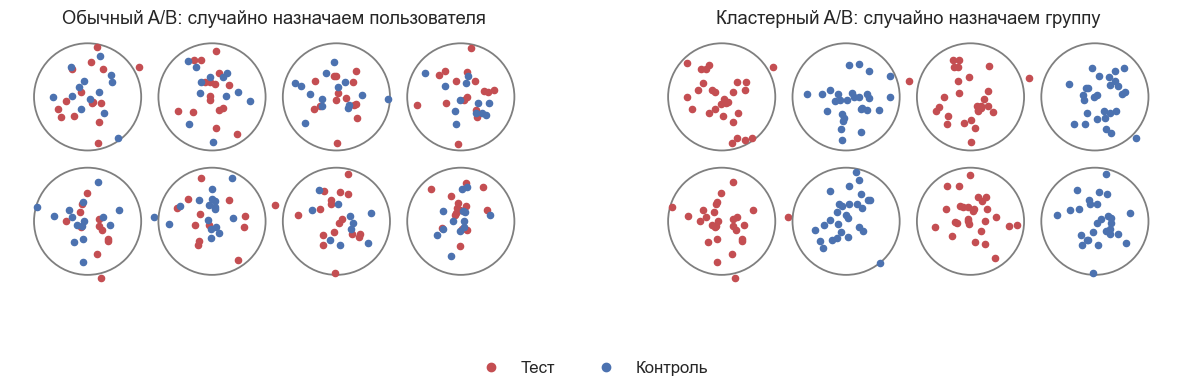

In [2]:
def plot_assignment(ax, by_cluster, title, seed=3):
    local = np.random.default_rng(seed)
    centers = np.array([(x, y) for x in range(4) for y in range(2)], dtype=float) * 2.6
    arms = local.permutation([0, 0, 0, 0, 1, 1, 1, 1])
    for center, arm in zip(centers, arms):
        points = center + local.normal(0, 0.42, (28, 2))
        treated = np.full(28, arm == 1) if by_cluster else local.random(28) < 0.5
        ax.add_patch(plt.Circle(center, 1.12, fill=False, color=GRAY, lw=1.3))
        ax.scatter(*points[treated].T, color=RED, s=20)
        ax.scatter(*points[~treated].T, color=BLUE, s=20)
    ax.set_aspect('equal')
    ax.set_axis_off()
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
plot_assignment(axes[0], False, 'Обычный A/B: случайно назначаем пользователя')
plot_assignment(axes[1], True, 'Кластерный A/B: случайно назначаем группу')
axes[1].scatter([], [], color=RED, label='Тест')
axes[1].scatter([], [], color=BLUE, label='Контроль')
fig.legend(*axes[1].get_legend_handles_labels(), loc='lower center', ncol=2, frameon=False);

Есть три равноправные причины так делать.

**1. Группы даны заранее, и делить внутри них невозможно или бессмысленно.** В магазине нельзя показать одну выкладку одному покупателю, а другую соседнему. Учитель работает с классом целиком, а курьеры обслуживают весь район. Здесь кластер — это физическая или организационная единица.

**2. Заражение и интерференция.** Пользователи влияют друг на друга, и контроль получает часть воздействия. Это нарушение SUTVA из лекции 2.02. Оно бывает разным:

* **заражение:** контроль узнаёт о воздействии, например промокод передают внутри компании или семьи;
* **сетевой эффект:** ценность продукта зависит от того, есть ли функция у друзей, например звонки в мессенджере;
* **конкуренция за ресурс:** на маркетплейсе тестовые продавцы забирают покупателей у контрольных.

Если часть $c$ контрольной группы получает полное воздействие, наблюдаемый эффект равен $(1-c)\tau$, то есть размывается. А при конкуренции за ресурс смещение может быть и вверх: тестовая группа выигрывает за счёт контрольной. В [кейсе Avito](https://habr.com/ru/companies/avito/articles/1043880/) тест по продавцам показал рост 88%, а настоящий эффект был 36%.

**3. Воздействие нельзя таргетировать на человека.** Реклама на ТВ и наружная реклама, цены и налоги в регионе, доставка в городе. Здесь кластер — география. Этот случай выделяют отдельно как **геоэксперименты**: кластеров мало, они очень разные, и нужны свои методы.

Кластерный дизайн не единственный выход.

| Ситуация | Что подходит |
| :--- | :--- |
| Пользователи независимы, можно таргетировать | Обычный A/B |
| Влияние через общий ресурс, эффект быстрый | Switchback (2.02) |
| Сравниваем ранжирование в одной выдаче | Interleaving (2.06) |
| Есть группы, граф или география, эффект может быть долгим | Кластерный A/B |
| Единиц очень мало, рандомизация невозможна | Синтетический контроль (2.09) |

Кластеризация убирает смещение между группами, но за это мы платим. Главная мысль лекции: **мощность теста определяется в первую очередь числом кластеров, а не числом пользователей**.

## Цена кластеризации: ICC и эффект дизайна

### Внутриклассовая корреляция

Пользователи одного кластера похожи: у них общий город, магазин или учитель. Запишем исход $i$-го пользователя в кластере $j$:

$$
Y_{ij} = \mu + u_j + e_{ij}, \qquad u_j \sim N(0, \sigma_u^2), \quad e_{ij} \sim N(0, \sigma_e^2)
$$

Здесь $u_j$ — общая добавка кластера. Доля дисперсии, которая приходится на различия между кластерами, называется **внутриклассовой корреляцией (intracluster correlation, ICC)**:

$$
\rho = \frac{\sigma_u^2}{\sigma_u^2 + \sigma_e^2}
$$

Это же корреляция исходов двух пользователей одного кластера. Значения обычно малы: в медицине и образовании часто порядка 0.01–0.2. Но малый ICC не значит малую проблему, потому что он умножается на размер кластера.

### Эффект дизайна

Среднее кластера размера $m$ имеет дисперсию

$$
\text{Var}(\bar{Y}_j) = \sigma_u^2 + \frac{\sigma_e^2}{m} = \frac{\sigma^2}{m}\big(1 + (m-1)\rho\big), \qquad \sigma^2 = \sigma_u^2 + \sigma_e^2
$$

Если бы $m$ пользователей были независимы, дисперсия была бы $\sigma^2/m$. Значит, кластеризация увеличивает дисперсию в

$$
DE = 1 + (m-1)\rho
$$

раз. Это **эффект дизайна (design effect)**. Эффективный размер выборки равен $n / DE$. При ICC 0.01 и 1000 пользователях в кластере $DE \approx 11$: из 100 000 пользователей остаётся эффективных около 9 000.

Если размеры кластеров разные, используют оценку с весами по размеру, то есть общее среднее по пользователям. Для неё формулу легко вывести. Дисперсия равна $\frac{1}{N^2}\sum_j n_j \sigma^2 (1 + (n_j - 1)\rho)$, откуда

$$
DE = 1 + \bigg(\frac{\sum n_j^2}{N} - 1\bigg)\rho = 1 + \big((CV^2 + 1)\bar{m} - 1\big)\rho
$$

где $CV$ — коэффициент вариации размеров кластеров. Эта формула известна как поправка Элдриджа и соавторов (2006). По [обзору](https://pmc.ncbi.nlm.nih.gov/articles/PMC8320970/) неравными размерами можно пренебречь при $CV$ ниже 0.23, а большие кластеры сильно увеличивают дисперсию. Проверим обе формулы симуляцией.

In [3]:
def simulated_de(sizes, icc, reps=200_000, seed=1):
    local = np.random.default_rng(seed)
    means = simulate_cluster_means(sizes, icc, reps, local)
    sizes = np.asarray(sizes, dtype=float)
    pooled = (means * sizes).sum(axis=1) / sizes.sum()
    return pooled.var() * sizes.sum()


rows = []
for name, sizes in [('Равные, m = 100', np.full(40, 100)),
                    ('CV = 0.5', 100 * (1 + 0.5 * st.norm.ppf((np.arange(40) + 0.5) / 40))),
                    ('CV около 1', np.exp(st.norm.ppf((np.arange(40) + 0.5) / 40) * 0.95 + 4))]:
    sizes = np.maximum(sizes, 5).round()
    cv = sizes.std() / sizes.mean()
    for icc in [0.01, 0.05]:
        rows.append({'Размеры': name, 'CV': cv, 'ICC': icc, 'DE по формуле': design_effect(sizes.mean(), icc, cv), 'DE в симуляции': simulated_de(sizes, icc)})
pd.DataFrame(rows).round(2)

,Размеры,CV,ICC,DE по формуле,DE в симуляции
0,"Равные, m = 100",0.00,0.01,1.99,1.98
1,"Равные, m = 100",0.00,0.05,5.95,5.94
2,CV = 0.5,0.48,0.01,2.23,2.23
3,CV = 0.5,0.48,0.05,7.14,7.15
4,CV около 1,1.05,0.01,2.74,2.74
5,CV около 1,1.05,0.05,9.71,9.73


Формула совпала с симуляцией: например, 9.71 и 9.73 при ICC 0.05 и $CV \approx 1$. Неравные размеры заметно ухудшают ситуацию: при тех же ICC и среднем размере эффект дизайна равен 9.7 вместо 6.

Теперь посмотрим, что это значит для теста. Подвигайте ICC и размер кластера. Эффект равен нулю: мы видим только шум, сравнивая две половины из 40 кластеров. Для сравнения показано распределение при том же числе пользователей и индивидуальной рандомизации.

In [4]:
def plot_noise(ax, icc, m, k=40, reps=4000, seed=2):
    local = np.random.default_rng(seed)
    means = simulate_cluster_means(np.full(k, m), icc, reps, local)
    treated = random_assignment(reps, k, local)
    estimate = (means * treated).sum(axis=1) / (k // 2) - (means * ~treated).sum(axis=1) / (k // 2)
    individual = local.normal(0, np.sqrt(4 / (k * m)), reps)
    bins = np.linspace(-1, 1, 61) * max(4 * estimate.std(), 0.02)
    ax.hist(individual, bins=bins, color=GRAY, alpha=0.6, label='Индивидуальная')
    ax.hist(estimate, bins=bins, color=BLUE, alpha=0.6, label='Кластерная')
    ax.set_title(f'ICC = {icc}, m = {m}: DE = {design_effect(m, icc):.1f}, SD выросло в {estimate.std() / individual.std():.1f} раза', fontsize=12)
    ax.set_xlabel('Оценка эффекта при нулевом настоящем эффекте')
    ax.legend(fontsize=10)


def noise_demo(icc=0.02, m=200):
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    plot_noise(ax, icc, m)
    plt.show()


interact(noise_demo,
         icc=FloatSlider(value=0.02, min=0, max=0.2, step=0.01, description='ICC'),
         m=IntSlider(value=200, min=10, max=2000, step=10, description='Размер'));

Статичная версия для трёх сочетаний.

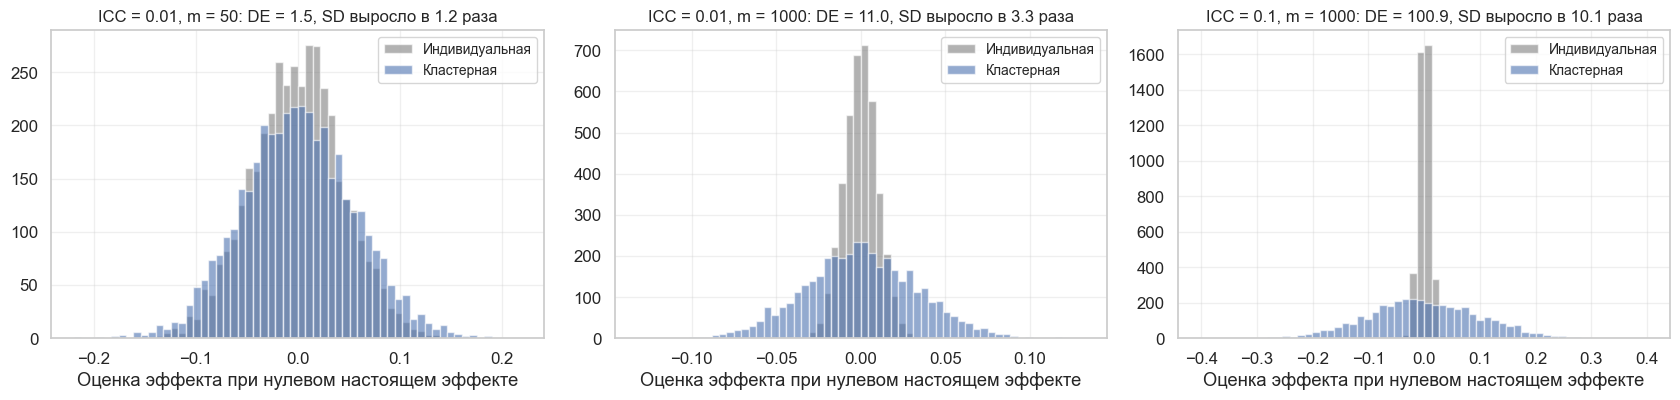

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, (icc, m) in zip(axes, [(0.01, 50), (0.01, 1000), (0.1, 1000)]):
    plot_noise(ax, icc, m)
plt.tight_layout()

### Что будет, если не заметить кластеры

Самая частая ошибка — назначить воздействие кластерам, а затем посчитать обычный t-тест по пользователям. Он считает пользователей независимыми, поэтому занижает дисперсию примерно в $DE$ раз. Посчитаем ошибку первого рода при $\alpha = 5\%$.

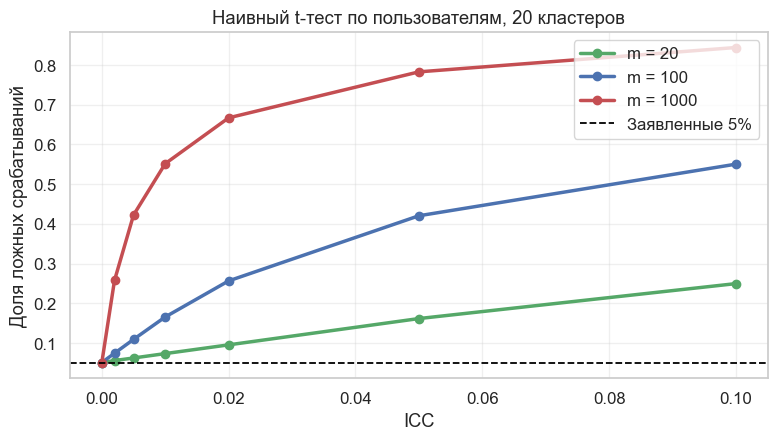

In [6]:
def naive_false_positive(icc, m, k=20):
    """Считает долю ложных срабатываний t-теста по пользователям по формуле занижения дисперсии."""
    return 2 * st.norm.sf(1.96 / np.sqrt(design_effect(m, icc)))


def simulated_false_positive(icc, m, k=20, reps=100_000, seed=4):
    local = np.random.default_rng(seed)
    means = simulate_cluster_means(np.full(k, m), icc, reps, local)
    treated = random_assignment(reps, k, local)
    estimate = (means * treated).sum(axis=1) / (k // 2) - (means * ~treated).sum(axis=1) / (k // 2)
    naive_se = np.sqrt(4 / (k * m))
    return np.mean(np.abs(estimate / naive_se) > 1.96)


iccs = np.array([0, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1])
fig, ax = plt.subplots(figsize=(9, 4.5))
for m, color in zip([20, 100, 1000], [GREEN, BLUE, RED]):
    ax.plot(iccs, [simulated_false_positive(icc, m) for icc in iccs], 'o-', color=color, lw=2.5, label=f'm = {m}')
ax.axhline(0.05, color='black', ls='--', lw=1.3, label='Заявленные 5%')
ax.set_xlabel('ICC')
ax.set_ylabel('Доля ложных срабатываний')
ax.set_title('Наивный t-тест по пользователям, 20 кластеров')
ax.legend();

Ошибка огромна даже при крошечном ICC. При ICC 0.002 и 1000 пользователях в кластере ложных срабатываний 26%, при ICC 0.01 уже 55%, а при ICC 0.05 почти 80%. ICC 0.01 выглядит пренебрежимо, но умножается на 1000.

### Мощность: число кластеров важнее их размера

При $k$ кластерах на группу размера $m$ минимальный обнаруживаемый эффект равен

$$
MDE = (t_{1-\alpha/2} + t_{1-\beta}) \sqrt{\frac{2\sigma^2 (1 + (m-1)\rho)}{k m}}
$$

где квантили берутся из распределения Стьюдента с $2(k-1)$ степенями свободы. Это стандартная поправка для кластерных испытаний: при малом $k$ она заметна. Заметьте, что при $m \to \infty$

$$
MDE \to (t_{1-\alpha/2} + t_{1-\beta}) \sqrt{\frac{2\sigma^2\rho}{k}}
$$

То есть рост числа пользователей внутри кластеров упирается в предел, который можно сдвинуть только числом кластеров. Посмотрим на это: сравним рост $m$ при фиксированном $k$ и рост $k$ при фиксированном общем числе пользователей.

In [7]:
def cluster_mde(k, m, icc, power=0.8, alpha=0.05):
    """Считает MDE в стандартных отклонениях для k кластеров на группу размера m."""
    df = 2 * (k - 1)
    return (st.t.ppf(1 - alpha / 2, df) + st.t.ppf(power, df)) * np.sqrt(2 * (1 + (m - 1) * icc) / (k * m))


def plot_mde(axes, icc):
    sizes = np.geomspace(10, 100_000, 60)
    for k, color in zip([10, 30, 100], [RED, BLUE, GREEN]):
        axes[0].plot(sizes, cluster_mde(k, sizes, icc), color=color, lw=2.5, label=f'k = {k} на группу')
        axes[0].axhline(cluster_mde(k, 1e12, icc), color=color, ls=':', lw=1.2)
    axes[0].set_xscale('log')
    axes[0].set_yscale('log')
    axes[0].set_yticks([0.03, 0.05, 0.1, 0.2, 0.4], ['0.03', '0.05', '0.1', '0.2', '0.4'])
    axes[0].minorticks_off()
    axes[0].set_xlabel('Пользователей в кластере')
    axes[0].set_ylabel('MDE, стандартные отклонения')
    axes[0].set_title(f'ICC = {icc}: при фиксированном числе кластеров рост упирается в предел', fontsize=12)
    axes[0].legend(fontsize=10)

    clusters = np.array([5, 10, 20, 50, 100, 200, 500, 1000, 2000])
    for total, color in zip([20_000, 200_000], [BLUE, RED]):
        axes[1].plot(clusters, cluster_mde(clusters, total / clusters, icc), 'o-', color=color, lw=2.5, label=f'{total:,} пользователей на группу'.replace(',', ' '))
    axes[1].set_xscale('log')
    axes[1].set_yscale('log')
    axes[1].set_yticks([0.01, 0.03, 0.1, 0.3], ['0.01', '0.03', '0.1', '0.3'])
    axes[1].minorticks_off()
    axes[1].set_xlabel('Кластеров на группу')
    axes[1].set_title('При том же числе пользователей лучше больше мелких кластеров', fontsize=12)
    axes[1].legend(fontsize=10)


def mde_demo(icc=0.02):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    plot_mde(axes, icc)
    plt.tight_layout()
    plt.show()


interact(mde_demo, icc=FloatSlider(value=0.02, min=0.001, max=0.2, step=0.001, readout_format='.3f', description='ICC'));

Статичная версия при ICC 0.02.

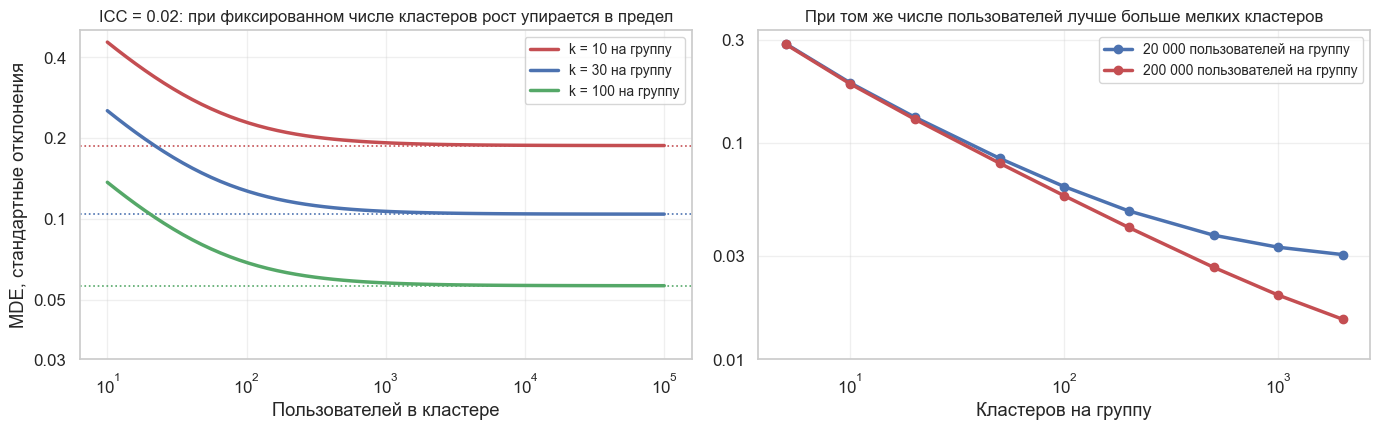

k = 30, m = 1000: DE = 21, MDE = 0.107 SD
k = 30, m = 10000: DE = 201, MDE = 0.104 SD
k = 300, m = 100: DE = 3, MDE = 0.040 SD
k = 300, m = 1000: DE = 21, MDE = 0.033 SD


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_mde(axes, 0.02)
plt.tight_layout()
plt.show()

for k, m in [(30, 1000), (30, 10_000), (300, 100), (300, 1000)]:
    print(f'k = {k}, m = {m}: DE = {design_effect(m, 0.02):.0f}, MDE = {cluster_mde(k, m, 0.02):.3f} SD')

Увеличение кластеров с 1000 до 10 000 пользователей почти ничего не даёт: MDE падает с 0.107 до 0.104. Увеличение числа кластеров с 30 до 300 снижает его втрое, до 0.033. На одних и тех же 30 000 пользователей на группу вариант из 300 кластеров по 100 человек даёт 0.040, а вариант из 30 кластеров по 1000 человек только 0.107.

Эта оценка опирается на постоянный ICC. При разбиении на более мелкие кластеры ICC обычно меняется, а главное, для интерференции мелкие кластеры хуже изолированы. Этот компромисс разобран ниже.

ICC при планировании берут из исторических данных: проведите A/A на прошлом периоде или оцените его дисперсионным анализом. Этот приём показан в разделе про школы.

## Единица рандомизации и единица анализа

В кластерном тесте **единица рандомизации (кластер) не совпадает с единицей анализа (пользователь)**. Это порождает два вопроса.

**Какой эффект мы оцениваем?** Есть две разные величины:

$$
\tau_{user} = \frac{\sum_j n_j \tau_j}{\sum_j n_j}, \qquad \tau_{cluster} = \frac{1}{k}\sum_j \tau_j
$$

Первая — средний эффект на пользователя, вторая — на кластер. Они совпадают, если эффект не зависит от размера кластера. Если большие города реагируют сильнее, они расходятся. Обычно бизнесу нужен эффект на пользователя, потому что деньги приносят пользователи. Но для политики в школе может быть важнее эффект на школу. Выбор надо сделать до теста.

**Как оценить?** Простая разница средних по кластерам оценивает $\tau_{cluster}$. Эффект на пользователя оценивает отношение сумм:

$$
\hat{R}_t = \frac{\sum_{j: T_j = t} S_j}{\sum_{j: T_j = t} n_j}, \qquad \hat{\tau}_{user} = \hat{R}_1 - \hat{R}_0
$$

где $S_j$ — сумма исхода в кластере. Это метрика отношения, потому что знаменатель случаен: в тест попали разные кластеры. Она имеет небольшое смещение порядка $1/k$, которое на больших $k$ незаметно, как отмечено в [работе Meta](https://ar5iv.labs.arxiv.org/html/2012.08591). Её дисперсию считают дельта-методом или линеаризацией, как в лекции 1.04 и практике 1.П1: для кластера берём $\psi_j = S_j - \hat{R}_t n_j$, и

$$
\widehat{\text{Var}}(\hat{R}_t) = \frac{\sum_{j} \psi_j^2}{N_t^2}
$$

Покажем, как расходятся две величины. Эффект здесь зависит от размера кластера.

In [9]:
def simulate_estimands(strength, k=60, reps=4000, seed=5):
    """Сравнивает две оценки при эффекте, растущем с размером кластера."""
    local = np.random.default_rng(seed)
    sizes = np.exp(st.norm.ppf((np.arange(k) + 0.5) / k) * 1.1 + 5)
    rank = (np.log(sizes) - np.log(sizes).mean()) / np.log(sizes).std()
    effect = 0.1 + strength * rank
    means = simulate_cluster_means(sizes, 0.02, reps, local)
    treated = random_assignment(reps, k, local)
    outcome = means + treated * effect
    cluster_estimate = (outcome * treated).sum(axis=1) / (k // 2) - (outcome * ~treated).sum(axis=1) / (k // 2)
    ratio_estimate = (outcome * sizes * treated).sum(axis=1) / (sizes * treated).sum(axis=1) - (outcome * sizes * ~treated).sum(axis=1) / (sizes * ~treated).sum(axis=1)
    return {'Эффект на кластер': effect.mean(), 'Среднее разницы по кластерам': cluster_estimate.mean(), 'SD разницы по кластерам': cluster_estimate.std(),
            'Эффект на пользователя': (effect * sizes).sum() / sizes.sum(), 'Среднее отношения сумм': ratio_estimate.mean(), 'SD отношения сумм': ratio_estimate.std()}


pd.DataFrame({strength: simulate_estimands(strength) for strength in [0, 0.05, 0.1]}).T.rename_axis('Зависимость от размера').round(3)

,Эффект на кластер,Среднее разницы по кластерам,SD разницы по кластерам,Эффект на пользователя,Среднее отношения сумм,SD отношения сумм
Зависимость от размера,,,,,,
0.00,0.1,0.101,0.046,0.100,0.101,0.060
0.05,0.1,0.102,0.046,0.152,0.151,0.061
0.10,0.1,0.102,0.048,0.203,0.201,0.064


Без связи с размером обе оценки близки к 0.10. При сильной связи эффект на пользователя равен 0.20, а на кластер 0.10. Разница средних по кластерам честно оценивает второе и не оценивает первое. Отношение сумм возвращает 0.20. Обе оценки верны, но отвечают на разные вопросы, поэтому важно выбрать величину заранее.

Обратите внимание на цену: отношение сумм шумнее, потому что большие кластеры получают больший вес, а эффективное число кластеров падает. Это та же поправка на неравные размеры.

## Как рандомизировать

При небольшом числе кластеров простая рандомизация часто даёт неравные группы: все большие города могут попасть в тест. Для этого есть несколько схем.

* **Простая рандомизация.** Случайно выбираем половину кластеров.
* **Стратификация.** Делим кластеры на слои, например по размеру или региону, и рандомизируем внутри слоя.
* **Парный дизайн (matched pairs).** Подбираем пары похожих кластеров и внутри пары случайно назначаем тест и контроль. Это предельный случай стратификации.
* **Повторная рандомизация и подбор групп.** Генерируем много случайных разбиений и берём лучшее по балансу.

[Имаи, Кинг и Налл (2009)](https://gking.harvard.edu/publication/the-essential-role-of-pair-matching-in-cluster-randomized-experiments-with-application-to-the-mexican-universal-health-insurance-evaluation/) показывают, что парный дизайн стоит использовать всегда, когда это возможно, а отказ от него равносилен потере значительной части данных. В их обзоре он использовался только в 19% из 106 опубликованных работ. Опасения, что в парах мало степеней свободы, важны лишь при очень слабой связи между парами.

**Главное правило: анализ должен соответствовать дизайну.** Если мы подобрали пары, анализируем разницы внутри пар. Если подбирали группы, тест должен это учитывать. Иначе обычный t-тест считает дисперсию так, будто рандомизация была простой, и становится консервативным.

Сравним схемы на 40 кластерах. Есть метрика до теста $x_j$, связанная с исходом с корреляцией $r$. Сравниваем точность и ошибку первого рода.

In [10]:
def balance_search(x, candidates, local):
    """Выбирает разбиение с лучшим балансом x среди случайных кандидатов."""
    k = len(x)
    options = np.argsort(local.random((candidates, k)), axis=1) < k // 2
    gap = np.abs((x * options).sum(axis=1) - (x * ~options).sum(axis=1))
    return options[np.argmin(gap)]


def compare_designs(r, k=40, reps=3000, candidates=500, seed=6):
    """Сравнивает схемы рандомизации при нулевом эффекте и единичной дисперсии кластера."""
    local = np.random.default_rng(seed)
    results = {name: {'estimate': [], 'p': []} for name in ['Простая, t-тест', 'Страты, t-тест в стратах', 'Пары, парный t-тест', 'Пары, обычный t-тест', 'Подбор групп, обычный t-тест', 'Подбор групп, ANCOVA']}

    def store(name, estimate, p):
        results[name]['estimate'].append(estimate)
        results[name]['p'].append(p)

    for _ in range(reps):
        x = local.normal(0, 1, k)
        y = r * x + np.sqrt(1 - r ** 2) * local.normal(0, 1, k)
        order = np.argsort(x)

        simple = local.permutation(np.arange(k) < k // 2)
        store('Простая, t-тест', y[simple].mean() - y[~simple].mean(), st.ttest_ind(y[simple], y[~simple]).pvalue)

        strata = order.reshape(4, k // 4)
        diffs = []
        for group in strata:
            arm = local.permutation(np.arange(len(group)) < len(group) // 2)
            diffs.append((y[group[arm]].mean() - y[group[~arm]].mean(), y[group[arm]].var(ddof=1) / arm.sum() + y[group[~arm]].var(ddof=1) / (~arm).sum()))
        diffs = np.array(diffs)
        estimate, se = diffs[:, 0].mean(), np.sqrt(diffs[:, 1].mean() / 4)
        store('Страты, t-тест в стратах', estimate, 2 * st.t.sf(abs(estimate / se), k - 8))

        pairs = order.reshape(k // 2, 2)
        flip = local.random(k // 2) < 0.5
        test, control = np.where(flip, pairs[:, 0], pairs[:, 1]), np.where(flip, pairs[:, 1], pairs[:, 0])
        d = y[test] - y[control]
        store('Пары, парный t-тест', d.mean(), st.ttest_1samp(d, 0).pvalue)
        store('Пары, обычный t-тест', d.mean(), st.ttest_ind(y[test], y[control]).pvalue)

        best = balance_search(x, candidates, local)
        store('Подбор групп, обычный t-тест', y[best].mean() - y[~best].mean(), st.ttest_ind(y[best], y[~best]).pvalue)
        beta = np.polyfit(x, y, 1)[0]
        residual = y - beta * x
        store('Подбор групп, ANCOVA', residual[best].mean() - residual[~best].mean(), st.ttest_ind(residual[best], residual[~best]).pvalue)

    return pd.DataFrame({name: {'SD оценки': np.std(v['estimate']), 'Ошибка I рода': np.mean(np.array(v['p']) < 0.05)} for name, v in results.items()}).T


def plot_designs(ax, table, r):
    y = np.arange(len(table))[::-1]
    ax.barh(y, table['SD оценки'], color=[GRAY, BLUE, GREEN, GREEN, ORANGE, ORANGE], height=0.65)
    ax.set_yticks(y, table.index)
    ax.set_xlabel('Стандартное отклонение оценки')
    ax.set_title(f'Корреляция метрики до теста с исходом r = {r}', fontsize=12)
    for row, value, error in zip(y, table['SD оценки'], table['Ошибка I рода']):
        ax.text(value + 0.005, row, f'ошибка I рода {error:.1%}', va='center', fontsize=10)
    ax.set_xlim(0, table['SD оценки'].max() * 1.5)


def designs_demo(r=0.8):
    fig, ax = plt.subplots(figsize=(9.5, 4.3))
    plot_designs(ax, compare_designs(r, reps=500, candidates=200), r)
    plt.show()


interact(designs_demo, r=FloatSlider(value=0.8, min=0, max=0.95, step=0.05, description='r'));

Статичная версия: слабая и сильная связь с метрикой до теста.

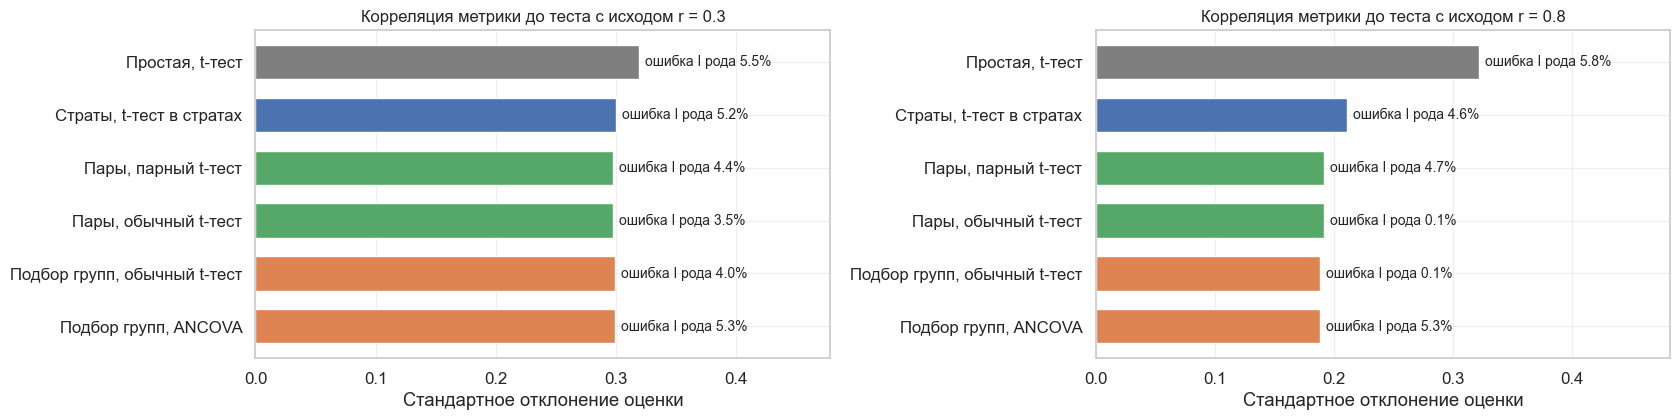

,SD оценки,Ошибка I рода
"Простая, t-тест",0.322,0.058
"Страты, t-тест в стратах",0.211,0.046
"Пары, парный t-тест",0.192,0.047
"Пары, обычный t-тест",0.192,0.001
"Подбор групп, обычный t-тест",0.188,0.001
"Подбор групп, ANCOVA",0.188,0.053


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.4))
design_tables = {}
for ax, r in zip(axes, [0.3, 0.8]):
    design_tables[r] = compare_designs(r)
    plot_designs(ax, design_tables[r], r)
plt.tight_layout()
plt.show()
design_tables[0.8].round(3)

При сильной связи ($r = 0.8$) стратификация снижает SD с 0.32 до 0.21, а пары и подбор групп до 0.19. Это почти вдвое, и такой же результат дал бы рост числа кластеров почти втрое. При слабой связи ($r = 0.3$) выигрыш мал, но и вреда нет.

Обратите внимание на строки с обычным t-тестом. Пары и подбор групп с ним дают ошибку первого рода 0.1% вместо 5%. Это не достижение, а признак несоответствия: тест считает дисперсию как при простой рандомизации и поэтому впустую теряет мощность. Парный t-тест и ANCOVA возвращают 5%.

Этот эффект виден и на практике. В [кейсе Avito](https://habr.com/ru/companies/avito/articles/1040162/) с оценкой времени обработки обращений единицей рандомизации был специалист поддержки, а не обращение. Их 20–150 на группу, то есть это кластерный тест с малым числом кластеров. Авторы собирали группы генетическим алгоритмом с балансом по профилю сотрудника. В A/A доля ложных срабатываний упала с 5.8–6.5% до 1% и ниже. Авторы воспринимают это как улучшение и не разбирают теорию. Наша симуляция добавляет важное уточнение: заниженная ошибка означает, что обычный тест перестал соответствовать дизайну. Лучше перейти к критерию, который её учитывает: добавить метрику до теста как ковариату (там же использован CUPED) либо считать p-value перестановками внутри допустимых разбиений.

## Как анализировать

Есть две стратегии: свернуть данные до кластеров или оставить пользователей и исправить дисперсию.

**1. Агрегация до кластеров.** Считаем метрику в каждом кластере и применяем t-тест к $k$ значениям. Это просто и честно: единица анализа совпадает с единицей рандомизации. При равных размерах оценка совпадает с регрессией, а интервал почти совпадает с CR2. При неравных размерах такой тест оценивает эффект на кластер, а не на пользователя.

**2. Кластеризованные стандартные ошибки (CRSE).** Для регрессии $Y_{ij} = \alpha + \tau T_j + e_{ij}$ оценка дисперсии

$$
\widehat{\text{Var}}(\hat{\beta}) = (X'X)^{-1} \bigg(\sum_{j=1}^{k} X_j' \hat{e}_j \hat{e}_j' X_j\bigg) (X'X)^{-1}
$$

разрешает любые зависимости внутри кластера. Для бинарного $T$ она равна дельта-методу из предыдущего раздела (вариант CR0). Варианты отличаются поправками:

* **CR1** умножает дисперсию на $\frac{k}{k-1}\frac{N-1}{N-2}$;
* **CR2** (Белл и Маккаффри) поправляет остатки на рычаг кластера. В нашем случае $\hat{\psi}_j$ делится на $\sqrt{1 - n_j/N_t}$, и степени свободы считаются по Саттертуэйту.

Эти оценки опираются на асимптотику по **числу кластеров**, поэтому при малом $k$ занижают дисперсию. [Камерон и Миллер (2015)](https://jhr.uwpress.org/content/50/2/317) отмечают, что твёрдой границы нет: «мало» может значить и меньше 20, и меньше 50 кластеров. Дисбаланс размеров ухудшает ситуацию.

**3. Wild cluster bootstrap.** Здесь мы фиксируем назначение и случайно меняем знак остатков кластера целиком: $y^*_j = \tilde{y}_j + w_j \tilde{e}_j$, $w_j = \pm 1$, где прогноз и остатки считаются при верной нулевой гипотезе. [Обзор Макиннона и соавторов](https://arxiv.org/pdf/2205.03285) рекомендует этот метод как основной при малом числе кластеров. Он сохраняет структуру внутри кластера.

**4. Рандомизационный вывод (permutation).** Перебираем назначения так же, как делали при запуске, и смотрим, где наша статистика. P-value равно $(1 + \#\{|t^*| \geq |t|\}) / (B + 1)$. Метод опирается только на дизайн, а его гарантия по ошибке первого рода точная, если воздействия нет ни у кого.

Почему кластеризовать вообще нужно? [Абади, Эйти, Имбенс и Вулдридж](https://arxiv.org/abs/1710.02926) объясняют: кластеризация — это вопрос дизайна. Ошибки надо кластеризовать на уровне, на котором назначалось воздействие. Корреляция сама по себе не повод: в обычном A/B с рандомизацией по пользователям не надо кластеризовать по городам, даже если исходы внутри города похожи.

Сначала убедимся, что дельта-метод — это CR0: сверим с `statsmodels`.

In [12]:
def cluster_statistics(means, sizes, treated):
    """Считает оценку и дисперсии CR0, CR1, CR2 для отношения сумм по матрице симуляций."""
    n1, n0 = (sizes * treated).sum(axis=-1, keepdims=True), (sizes * ~treated).sum(axis=-1, keepdims=True)
    r1, r0 = (means * sizes * treated).sum(axis=-1, keepdims=True) / n1, (means * sizes * ~treated).sum(axis=-1, keepdims=True) / n0
    estimate = (r1 - r0)[..., 0]
    psi = sizes * (means - np.where(treated, r1, r0))
    share = np.where(treated, n1, n0)
    v1 = (psi ** 2 * treated).sum(axis=-1) / n1[..., 0] ** 2
    v0 = (psi ** 2 * ~treated).sum(axis=-1) / n0[..., 0] ** 2
    cr2_t = (psi ** 2 / (1 - sizes / share) * treated).sum(axis=-1) / n1[..., 0] ** 2
    cr2_c = (psi ** 2 / (1 - sizes / share) * ~treated).sum(axis=-1) / n0[..., 0] ** 2
    return estimate, v1 + v0, cr2_t, cr2_c


check = np.random.default_rng(7)
k_check = 12
sizes_check = check.integers(20, 200, k_check)
arm = np.arange(k_check) % 2 == 0
frame = pd.DataFrame({'cluster': np.repeat(np.arange(k_check), sizes_check), 'treated': np.repeat(arm.astype(int), sizes_check)})
frame['y'] = 0.3 * frame['treated'] + np.repeat(check.normal(0, 0.3, k_check), sizes_check) + check.normal(0, 1, len(frame))

grouped = frame.groupby('cluster')['y'].mean().to_numpy()
estimate, cr0, _, _ = cluster_statistics(grouped, sizes_check.astype(float), arm)
fit = smf.ols('y ~ treated', frame).fit(cov_type='cluster', cov_kwds={'groups': frame['cluster'], 'use_correction': False})
print(f'Оценка: наша {float(estimate):.5f}, statsmodels {fit.params["treated"]:.5f}')
print(f'SE:     наша {np.sqrt(float(cr0)):.5f}, statsmodels {fit.bse["treated"]:.5f}')

Оценка: наша 0.21486, statsmodels 0.21486
SE:     наша 0.12080, statsmodels 0.12080


Оценка и стандартная ошибка совпали до пятого знака: дельта-метод для разницы отношений и CR0 — это одно и то же.

Теперь главный график лекции: какая ошибка первого рода у каждого метода в зависимости от числа кластеров. Сравним равные размеры кластеров и сильно разные ($CV \approx 1$), ICC 0.05.

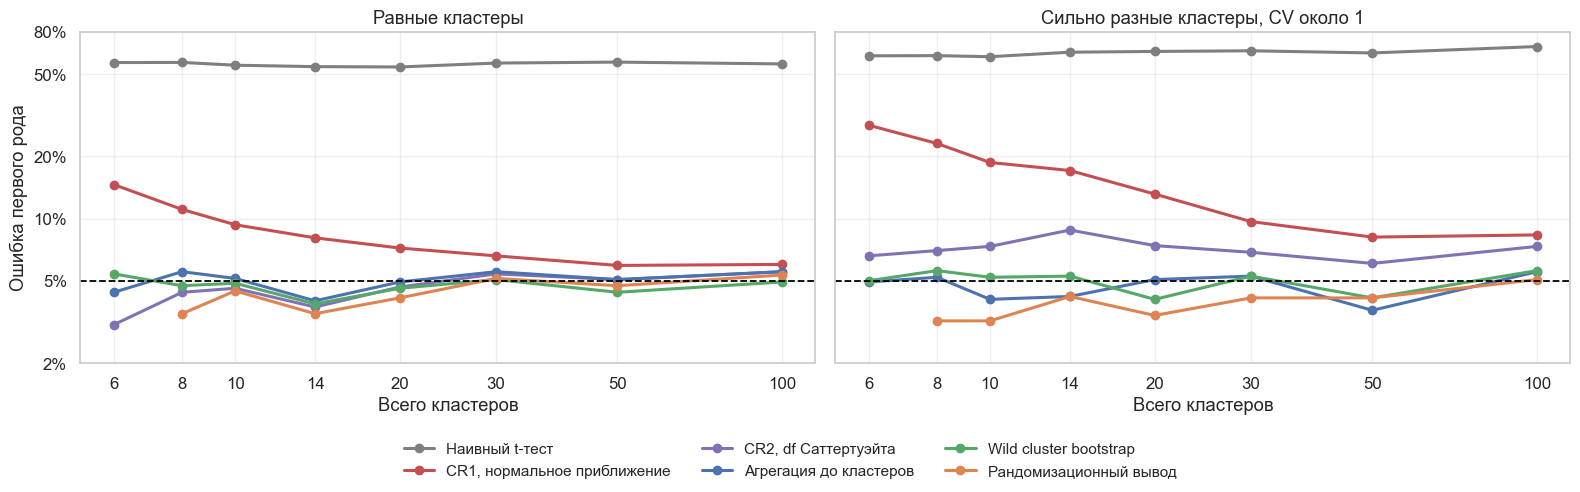

,Наивный t-тест,"CR1, нормальное приближение","CR2, df Саттертуэйта",Агрегация до кластеров,Wild cluster bootstrap,Рандомизационный вывод
6,0.612,0.283,0.066,0.049,0.050,0.000
8,0.613,0.231,0.070,0.052,0.056,0.032
10,0.606,0.187,0.073,0.041,0.052,0.032
14,0.637,0.171,0.088,0.042,0.053,0.042
20,0.643,0.131,0.074,0.051,0.041,0.034
30,0.647,0.097,0.069,0.053,0.053,0.041
50,0.632,0.081,0.061,0.036,0.041,0.041
100,0.679,0.083,0.073,0.055,0.056,0.051


In [13]:
def sizes_for(k, unequal, base=200):
    if not unequal:
        return np.full(k, float(base))
    quantiles = st.norm.ppf((np.arange(k) + 0.5) / k)
    return np.maximum(np.exp(quantiles * 0.95 + np.log(base) - 0.45), 5).round()


def error_rates(k, unequal, effect=0.0, icc=0.05, reps=1500, boot=199, seed=8):
    """Считает долю отклонений H0 разными методами при заданном эффекте."""
    local = np.random.default_rng(seed + k + int(unequal))
    sizes = sizes_for(k, unequal)
    means = simulate_cluster_means(sizes, icc, reps, local)
    treated = random_assignment(reps, k, local)
    means = means + effect * treated
    G = k // 2

    estimate, cr0, cr2_t, cr2_c = cluster_statistics(means, sizes, treated)
    N = sizes.sum()
    cr1 = cr0 * k / (k - 1) * (N - 1) / (N - 2)
    t_cr1 = estimate / np.sqrt(cr1)
    cr2 = cr2_t + cr2_c
    df = cr2 ** 2 / (cr2_t ** 2 / (G - 1) + cr2_c ** 2 / (G - 1))

    naive_se = np.sqrt(4 / sizes.sum())
    cluster_t = st.ttest_ind(np.where(treated, means, np.nan), np.where(treated, np.nan, means), axis=1, nan_policy='omit').pvalue
    cluster_t = np.asarray(cluster_t, dtype=float)

    rejected = {'Наивный t-тест': np.abs(estimate / naive_se) > 1.96,
                'CR1, нормальное приближение': np.abs(t_cr1) > 1.96,
                'CR2, df Саттертуэйта': 2 * st.t.sf(np.abs(estimate) / np.sqrt(cr2), df) < 0.05,
                'Агрегация до кластеров': cluster_t < 0.05}

    wild, permutation = np.zeros(reps, bool), np.zeros(reps, bool)
    for rep in range(reps):
        y, arm = means[rep], treated[rep]
        pooled = (y * sizes).sum() / N
        signs = local.choice([-1.0, 1.0], (boot, k))
        star = pooled + signs * (y - pooled)
        boot_est, boot_var, _, _ = cluster_statistics(star, sizes, arm[None, :])
        wild[rep] = (1 + np.sum(np.abs(boot_est / np.sqrt(boot_var)) >= abs(estimate[rep] / np.sqrt(cr0[rep])))) / (boot + 1) < 0.05

        options = np.argsort(local.random((boot, k)), axis=1) < G
        perm_est, perm_var, _, _ = cluster_statistics(np.broadcast_to(y, (boot, k)), sizes, options)
        permutation[rep] = (1 + np.sum(np.abs(perm_est / np.sqrt(perm_var)) >= abs(estimate[rep] / np.sqrt(cr0[rep])))) / (boot + 1) < 0.05

    rejected['Wild cluster bootstrap'] = wild
    rejected['Рандомизационный вывод'] = permutation
    return {name: value.mean() for name, value in rejected.items()}


cluster_counts = [6, 8, 10, 14, 20, 30, 50, 100]
false_positive = {unequal: pd.DataFrame({k: error_rates(k, unequal) for k in cluster_counts}).T for unequal in [False, True]}

METHOD_COLORS = {'Наивный t-тест': GRAY, 'CR1, нормальное приближение': RED, 'CR2, df Саттертуэйта': PURPLE,
                 'Агрегация до кластеров': BLUE, 'Wild cluster bootstrap': GREEN, 'Рандомизационный вывод': ORANGE}

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, unequal, title in zip(axes, [False, True], ['Равные кластеры', 'Сильно разные кластеры, CV около 1']):
    table = false_positive[unequal]
    for method, color in METHOD_COLORS.items():
        ax.plot(table.index, table[method].replace(0, np.nan), 'o-', color=color, lw=2.2, label=method)
    ax.axhline(0.05, color='black', ls='--', lw=1.3)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.minorticks_off()
    ax.set_xticks(cluster_counts, cluster_counts)
    ax.set_yticks([0.02, 0.05, 0.1, 0.2, 0.5, 0.8], ['2%', '5%', '10%', '20%', '50%', '80%'])
    ax.set_xlabel('Всего кластеров')
    ax.set_title(title)
axes[0].set_ylabel('Ошибка первого рода')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, frameon=False, fontsize=11)
plt.tight_layout(rect=(0, 0.11, 1, 1))
plt.show()
false_positive[True].round(3)

* Наивный t-тест ошибается в 55–68% случаев и при равных, и при разных кластерах, причём число кластеров ему не помогает.
* CR1 с нормальным приближением заметно занижает дисперсию при малом $k$: при разных размерах 28% ложных срабатываний на 6 кластерах, 13% на 20 и всё ещё 8% на 100. Выходит, что «100 кластеров достаточно» неверно при сильном дисбалансе.
* CR2 с поправкой степеней свободы гораздо лучше: 6.6–8.8%. Здесь используется упрощённая формула степеней свободы.
* Агрегация и wild bootstrap держат уровень около 5%.
* Рандомизационный вывод слегка консервативен. На 6 кластерах его нельзя применить: существует всего 20 разбиений, поэтому минимальное двустороннее p-value равно 0.1, и значимость недостижима. Это важное практическое ограничение: при малом числе кластеров заранее посчитайте, сколько возможно разбиений.

Посмотрим на мощность тех методов, которые держат уровень, при эффекте 0.15 стандартного отклонения.

In [14]:
power_counts = [10, 20, 50, 100]
power = pd.DataFrame({k: error_rates(k, True, effect=0.15, reps=800) for k in power_counts}).T[['CR2, df Саттертуэйта', 'Агрегация до кластеров', 'Wild cluster bootstrap', 'Рандомизационный вывод']]
power.rename_axis('Кластеров').round(3)

,"CR2, df Саттертуэйта",Агрегация до кластеров,Wild cluster bootstrap,Рандомизационный вывод
Кластеров,,,,
10,0.184,0.149,0.150,0.089
20,0.258,0.264,0.192,0.184
50,0.395,0.542,0.361,0.350
100,0.648,0.851,0.601,0.605


Мощность низка при любом методе: при 20 кластерах 18–26%, при 100 только 60–85%. Агрегация здесь мощнее, потому что каждый кластер весит одинаково, а большие кластеры не забирают вес. Но здесь эффект одинаков во всех кластерах, и она оценивает эффект на кластер. Если эффект зависит от размера, это другая величина, поэтому выбирать метод только по мощности нельзя.

Для снижения дисперсии работает CUPED на уровне кластера: добавляем в регрессию значение метрики до теста, посчитанное по кластеру. В работе Meta такая корректировка снизила стандартные ошибки более чем на 30%. Здесь выигрыш может быть больше, чем в обычном тесте, потому что среднее кластера стабильно во времени: шум пользователей усредняется, а $u_j$ остаётся.

## Сценарий: готовые группы

Школы, магазины, отделения банка, классы. Кластеры заданы, граф не нужен. Возьмём данные о мышлении роста из лекций 2.09 и 2.10: 10 391 ученик из 76 школ. Данные смоделированы Эйти и Вейджером по настоящему исследованию, но структура кластеров реалистична. Оценим ICC и посмотрим, что бы было, если бы семинар назначался школам целиком.

ICC оцениваем дисперсионным анализом:

$$
\hat{\rho} = \frac{MSB - MSW}{MSB + (m_0 - 1) MSW}, \qquad m_0 = \frac{N - \sum n_j^2 / N}{k - 1}
$$

где $MSB$ и $MSW$ — средние квадраты между и внутри кластеров.

Школ: 76, средний размер 137, CV размеров 0.73
ICC = 0.088, эффект дизайна = 19.3, эффективных учеников из 10391: 539
Корреляция среднего балла школы с показателем до теста: 0.05


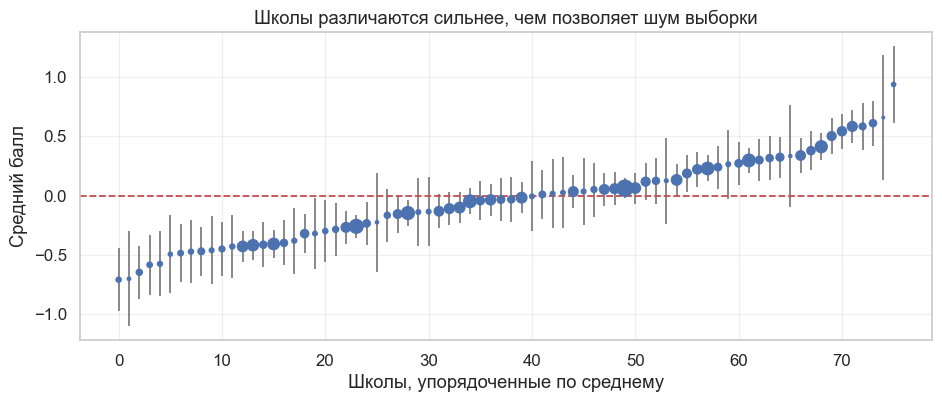

In [15]:
schools = pd.read_csv(DATA + 'learning_mindset.csv')
outcome_school = schools.groupby('schoolid').agg(n=('achievement_score', 'size'), y=('achievement_score', 'mean'), pre=('school_achievement', 'first'))


def anova_icc(data, cluster, value):
    groups = data.groupby(cluster)[value]
    sizes, means = groups.size(), groups.mean()
    N, k = sizes.sum(), len(sizes)
    grand = data[value].mean()
    msb = (sizes * (means - grand) ** 2).sum() / (k - 1)
    msw = ((data[value] - groups.transform('mean')) ** 2).sum() / (N - k)
    m0 = (N - (sizes ** 2).sum() / N) / (k - 1)
    return (msb - msw) / (msb + (m0 - 1) * msw)


icc_school = anova_icc(schools, 'schoolid', 'achievement_score')
sizes_school = outcome_school['n'].to_numpy(float)
cv_school = sizes_school.std() / sizes_school.mean()
de_school = design_effect(sizes_school.mean(), icc_school, cv_school)
print(f'Школ: {len(sizes_school)}, средний размер {sizes_school.mean():.0f}, CV размеров {cv_school:.2f}')
print(f'ICC = {icc_school:.3f}, эффект дизайна = {de_school:.1f}, эффективных учеников из {len(schools)}: {len(schools) / de_school:.0f}')
print(f"Корреляция среднего балла школы с показателем до теста: {outcome_school['y'].corr(outcome_school['pre']):.2f}")

order = outcome_school.sort_values('y')
fig, ax = plt.subplots(figsize=(11, 4))
ax.vlines(np.arange(len(order)), order['y'] - 1.96 * schools['achievement_score'].std() / np.sqrt(order['n']), order['y'] + 1.96 * schools['achievement_score'].std() / np.sqrt(order['n']), color=GRAY, lw=1.3)
ax.scatter(np.arange(len(order)), order['y'], color=BLUE, s=order['n'] / 4, zorder=3)
ax.axhline(schools['achievement_score'].mean(), color=RED, ls='--', lw=1.3)
ax.set_xlabel('Школы, упорядоченные по среднему')
ax.set_ylabel('Средний балл')
ax.set_title('Школы различаются сильнее, чем позволяет шум выборки');

Проведём **A/A на этих данных**: многократно случайно делим школы пополам, не применяя воздействия. Заодно добавим искусственный эффект и оценим мощность. Это ровно тот пайплайн, который [X5](https://habr.com/ru/companies/X5Tech/articles/466349/) использует для магазинов: подбор групп, проверка равенства в предпилотном периоде, добавление искусственного эффекта и браковка метода, если ошибки выходят за порог. Сравним простое разбиение и пары по средней успеваемости школы до теста.

In [16]:
def school_aa(paired, effect=0.0, reps=3000, seed=9):
    """Делит школы на группы и считает долю значимых результатов."""
    local = np.random.default_rng(seed)
    ordered = outcome_school.sort_values('pre')
    y, n = ordered['y'].to_numpy(), ordered['n'].to_numpy(float)
    k = len(y) - len(y) % 2
    y, n = y[:k], n[:k]
    naive_se = schools['achievement_score'].std() * np.sqrt(1 / (n.sum() / 2) * 2)
    estimates, cluster_p, paired_p, naive = [], [], [], []
    for _ in range(reps):
        if paired:
            flip = local.random(k // 2) < 0.5
            arm = np.zeros(k, bool)
            arm[np.arange(0, k, 2) + flip] = True
        else:
            arm = local.permutation(np.arange(k) < k // 2)
        outcome = y + effect * arm
        ratio = (outcome * n * arm).sum() / (n * arm).sum() - (outcome * n * ~arm).sum() / (n * ~arm).sum()
        estimates.append(ratio)
        naive.append(abs(ratio / naive_se) > 1.96)
        cluster_p.append(st.ttest_ind(outcome[arm], outcome[~arm]).pvalue < 0.05)
        if paired:
            first, second = outcome[0::2], outcome[1::2]
            sign = np.where(arm[0::2], 1, -1)
            paired_p.append(st.ttest_1samp(sign * (first - second), 0).pvalue < 0.05)
    result = {'SD оценки': np.std(estimates), 'Наивный тест': np.mean(naive), 'Тест по школам': np.mean(cluster_p)}
    if paired:
        result['Парный тест'] = np.mean(paired_p)
    return result


pd.DataFrame({'Простое разбиение, A/A': school_aa(False), 'Пары, A/A': school_aa(True),
              'Простое разбиение, эффект 0.2': school_aa(False, 0.2), 'Пары, эффект 0.2': school_aa(True, 0.2)}).T.round(3)

,SD оценки,Наивный тест,Тест по школам,Парный тест
"Простое разбиение, A/A",0.078,0.626,0.052,NaN
"Пары, A/A",0.076,0.632,0.047,0.049
"Простое разбиение, эффект 0.2",0.078,0.981,0.669,NaN
"Пары, эффект 0.2",0.076,0.984,0.673,0.660


ICC равен 0.088, а эффект дизайна 19.3: из 10 391 ученика эффективных остаётся около 540. На A/A наивный тест ошибается в 63% случаев, а тест по школам в 5%. При эффекте 0.2 у наивного теста «мощность» 98%, но это мнимая цифра: честная мощность 67%.

Пары здесь почти не помогли: SD 0.076 против 0.078. Причина видна из вывода выше: показатель школы до теста слабо связан со средним баллом, корреляция равна всего 0.05. Паровать надо по признаку, который реально предсказывает исход. В магазинах им обычно становится сама метрика в прошлом периоде, поэтому X5 подбирает пары по её истории и трендам.

## Сценарий: интерференция и кластеры на графе

Если пользователи связаны, важно, как устроены их связи. Запишем потенциальный исход в общем виде: он зависит от всего вектора назначений, $Y_i(\mathbf{z})$. Интересует **глобальный эффект** — разница между миром, где воздействие у всех, и миром, где его нет:

$$
GTE = \frac{1}{n}\sum_i \big(Y_i(\mathbf{1}) - Y_i(\mathbf{0})\big)
$$

В обычном A/B у пользователя половина друзей в тесте, а половина в контроле, поэтому мы не видим ни один из этих миров. Простейшая модель делит эффект на прямой $\tau$ и сетевой $\gamma$:

$$
Y_i = \alpha + \tau z_i + \gamma \cdot \text{доля друзей в тесте} + e_i, \qquad GTE = \tau + \gamma
$$

При индивидуальной рандомизации доля друзей в тесте примерно равна 0.5 у всех, и оценка улавливает только $\tau$. Если друзья находятся в одном кластере, то у тестовых доля близка к 1, а у контрольных к 0, и мы видим почти весь $\gamma$.

Идеальных кластеров нет: граф обычно нельзя разрезать, не задев связей. Качество разбиения измеряют **чистотой (purity)**: долей связей, лежащих внутри кластеров. Именно она определяет, какая часть $\gamma$ видна. При чистоте 0% мы возвращаемся к пользовательскому тесту.

Граф делят алгоритмами кластеризации. **Louvain** жадно максимизирует модулярность и даёт сообщества очень разного размера. Параметр разрешения задаёт, сколько будет кластеров. **Сбалансированное разбиение** (balanced partitioning, reLDG, METIS) даёт равные части. У [Meta](https://ar5iv.labs.arxiv.org/html/2012.08591) Louvain при той же мощности давал большую чистоту, поэтому авторы не советуют настаивать на равных кластерах. [LinkedIn](https://faculty.washington.edu/msaveski/assets/publications/2017_detecting_network_effects/paper.pdf) использует сбалансированный reLDG: при 1000 кластеров внутри них 35.6% связей, а при 10 000 только 21.1%. Заметьте, насколько чистота далека от 100% на реальном графе.

Построим граф с 40 сообществами разного размера и разобьём его с разным разрешением.

Пользователей: 2354, связей: 6868, средняя степень: 5.8


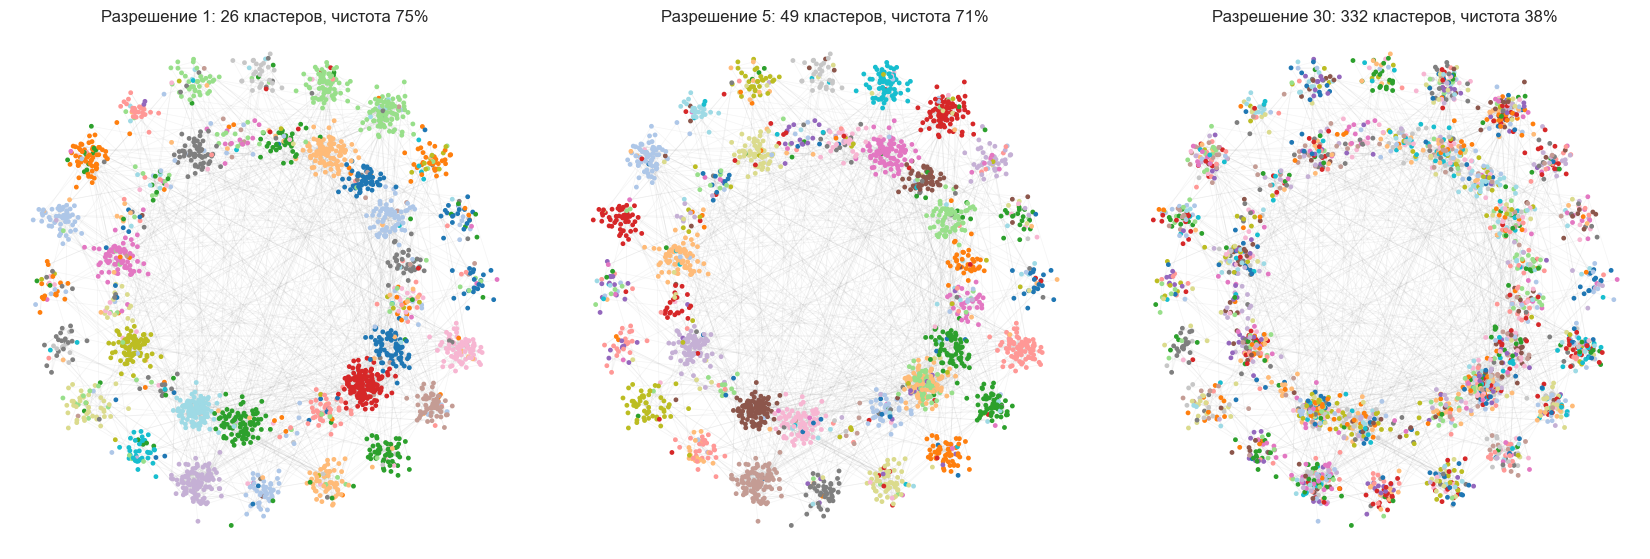

In [17]:
def build_graph(seed=10, communities=40, inside=0.06, outside=0.0006):
    """Создаёт граф сообществ разного размера и его матрицу смежности."""
    local = np.random.default_rng(seed)
    sizes = np.maximum(np.exp(local.normal(4.1, 0.6, communities)), 15).astype(int).tolist()
    probabilities = np.full((communities, communities), outside)
    np.fill_diagonal(probabilities, inside)
    graph = nx.stochastic_block_model(sizes, probabilities.tolist(), seed=seed)
    graph.remove_nodes_from([node for node, degree in dict(graph.degree()).items() if degree == 0])
    return nx.convert_node_labels_to_integers(graph)


graph = build_graph()
adjacency = nx.to_scipy_sparse_array(graph, format='csr', dtype=float)
degree = np.asarray(adjacency.sum(axis=1)).ravel()
block = np.array([graph.nodes[node]['block'] for node in graph.nodes])
print(f'Пользователей: {graph.number_of_nodes()}, связей: {graph.number_of_edges()}, средняя степень: {degree.mean():.1f}')


def partition_labels(resolution):
    communities = nx.community.louvain_communities(graph, resolution=resolution, seed=1)
    labels = np.zeros(graph.number_of_nodes(), dtype=int)
    for index, members in enumerate(communities):
        labels[list(members)] = index
    return labels


def purity(labels):
    rows, cols = adjacency.nonzero()
    return np.mean(labels[rows] == labels[cols])


layout = np.random.default_rng(2)
angles = 2 * np.pi * np.arange(block.max() + 1) / (block.max() + 1)
radius = np.where(np.arange(block.max() + 1) % 2 == 0, 3.2, 2.2)
centers = np.column_stack([radius * np.cos(angles), radius * np.sin(angles)])
positions = centers[block] + layout.normal(0, 0.16, (len(block), 2))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
rows, cols = adjacency.nonzero()
shown = layout.choice(len(rows), 2500, replace=False)
for ax, resolution in zip(axes, [1, 5, 30]):
    labels = partition_labels(resolution)
    ax.plot(np.stack([positions[rows[shown], 0], positions[cols[shown], 0]]), np.stack([positions[rows[shown], 1], positions[cols[shown], 1]]), color=GRAY, alpha=0.08, lw=0.5)
    ax.scatter(*positions.T, c=labels % 20, cmap='tab20', s=6, zorder=3)
    ax.set_aspect('equal')
    ax.set_title(f'Разрешение {resolution}: {labels.max() + 1} кластеров, чистота {purity(labels):.0%}', fontsize=12)
    ax.set_axis_off()
plt.tight_layout()

Теперь оценим компромисс. Мельче кластеры — меньше дисперсия, но ниже чистота и больше смещение. Запустим много симуляций кластерного теста для каждого разбиения с прямым эффектом $\tau = 0.1$ и сетевым $\gamma = 0.1$. Индивидуальная рандомизация — это предельный случай, где каждый пользователь сам себе кластер.

In [18]:
def run_partition(labels, tau=0.1, gamma=0.1, icc=0.02, reps=1000, seed=11):
    """Возвращает среднее и SD оценки разницы средних при данном разбиении."""
    local = np.random.default_rng(seed)
    n, k = len(labels), labels.max() + 1
    home = local.normal(0, np.sqrt(icc), block.max() + 1)[block]
    estimates = np.zeros(reps)
    for rep in range(reps):
        arm = local.permutation(np.arange(k) < k // 2)[labels].astype(float)
        share = adjacency @ arm / np.maximum(degree, 1)
        y = tau * arm + gamma * share + home + local.normal(0, np.sqrt(1 - icc), n)
        estimates[rep] = y[arm == 1].mean() - y[arm == 0].mean()
    return estimates.mean(), estimates.std()


individual_mean, individual_sd = run_partition(np.arange(graph.number_of_nodes()))
rows = [{'Разбиение': 'Индивидуально', 'Кластеров': graph.number_of_nodes(), 'Чистота': 0.0, 'Среднее': individual_mean, 'SD': individual_sd}]
for resolution in [0.3, 1, 3, 5, 10, 30, 100]:
    labels = partition_labels(resolution)
    mean, sd = run_partition(labels)
    rows.append({'Разбиение': f'Louvain {resolution}', 'Кластеров': labels.max() + 1, 'Чистота': purity(labels), 'Среднее': mean, 'SD': sd})
partitions = pd.DataFrame(rows).sort_values('Кластеров').reset_index(drop=True)
partitions['Видимая доля gamma'] = ((partitions['Среднее'] - 0.1) / 0.1).round(3)
partitions.round(3)

,Разбиение,Кластеров,Чистота,Среднее,SD,Видимая доля gamma
0,Louvain 0.3,8,0.841,0.177,0.086,0.768
1,Louvain 1,26,0.752,0.175,0.058,0.755
2,Louvain 3,40,0.744,0.176,0.053,0.756
3,Louvain 5,49,0.711,0.170,0.053,0.696
4,Louvain 10,104,0.534,0.159,0.046,0.588
5,Louvain 30,332,0.377,0.142,0.043,0.420
6,Louvain 100,763,0.265,0.135,0.042,0.352
7,Индивидуально,2354,0.000,0.099,0.040,-0.013


Настоящий глобальный эффект равен 0.20. Индивидуальная рандомизация даёт 0.10: сетевая часть не видна вообще, а SD минимальна, 0.040. Louvain с 40 кластерами и чистотой 74% показывает 0.176 при SD 0.053, то есть почти убирает смещение за небольшую цену. Укрупнение до 8 кластеров мало что добавляет: чистота 84%, а SD выросла до 0.086. Измельчение до 763 кластеров теряет больше половины сетевого эффекта. Видимая доля $\gamma$ близка к чистоте, потому что соседи вне кластера в среднем наполовину в тесте. Чистота считается по рёбрам, а видимая доля по пользователям, поэтому точного совпадения нет.

Какое разбиение лучше, зависит от силы сетевого эффекта. Подвигайте $\gamma$. Смещение линейно зависит от него, а дисперсию мы измерили выше, поэтому ошибку легко пересчитать: $RMSE^2 = \text{смещение}^2 + SD^2$.

In [19]:
def plot_tradeoff(ax, gamma):
    table = partitions.copy()
    table['Смещение'] = gamma * (1 - table['Видимая доля gamma'])
    table['RMSE'] = np.sqrt(table['Смещение'] ** 2 + table['SD'] ** 2)
    ax.plot(table['Кластеров'], table['Смещение'].abs(), 'o-', color=RED, lw=2.2, label='|Смещение|')
    ax.plot(table['Кластеров'], table['SD'], 'o-', color=BLUE, lw=2.2, label='SD')
    ax.plot(table['Кластеров'], table['RMSE'], 'o-', color='black', lw=2.8, label='RMSE')
    best = table.loc[table['RMSE'].idxmin()]
    ax.scatter([best['Кластеров']], [best['RMSE']], s=170, facecolors='none', edgecolors=GREEN, linewidths=2.5, zorder=4, label=f"Лучшее: {best['Кластеров']:.0f} кластеров")
    ax.set_xscale('log')
    ax.set_xlabel('Число кластеров')
    ax.set_ylabel('Ошибка оценки GTE')
    ax.set_title(f'Сетевой эффект γ = {gamma}', fontsize=12)
    ax.legend(fontsize=10)


def tradeoff_demo(gamma=0.1):
    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    plot_tradeoff(ax, gamma)
    plt.show()


interact(tradeoff_demo, gamma=FloatSlider(value=0.1, min=0, max=0.5, step=0.01, description='γ'));

Статичная версия для слабого, среднего и сильного сетевого эффекта.

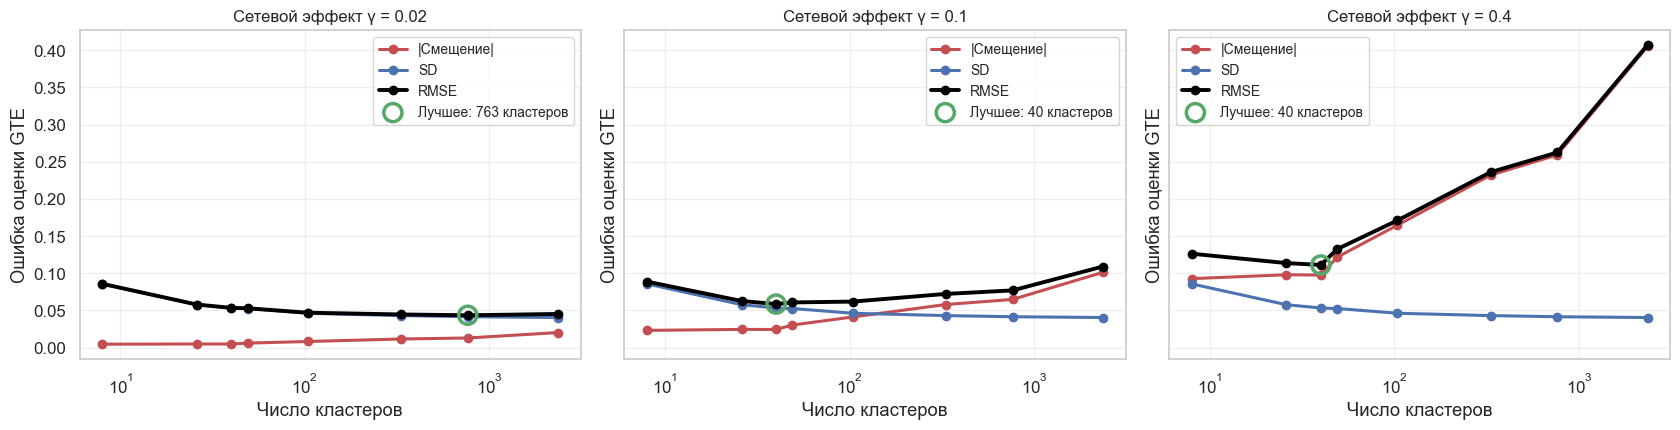

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, gamma in zip(axes, [0.02, 0.1, 0.4]):
    plot_tradeoff(ax, gamma)
plt.tight_layout()

При слабом сетевом эффекте ($\gamma = 0.02$) выгодны мелкие кластеры: смещение мало, и лучше 763 кластера. При среднем и сильном эффекте лучше всего 40 кластеров, совпадающих с настоящими сообществами. Там виден излом: дальше кластеры дробятся, и смещение резко растёт. Настоящую силу эффекта мы заранее не знаем, поэтому полезны проверки из следующего раздела.

Именно этот компромисс разбирает [работа Вивиано и соавторов](https://arxiv.org/abs/2310.14983). Они показывают, что худшее смещение определяется долей соседей вне кластера, а дисперсия — суммой квадратов размеров кластеров, и выбирать кластеры надо под задачу оценки эффекта, а не под поиск сообществ.

Несколько практических приёмов.

* **Назначаем по кластеру, а воздействуем по пользователю.** [Meta](https://medium.com/@AnalyticsAtMeta/how-meta-tests-products-with-strong-network-effects-96003a056c2c) рандомизирует кластеры, но показывает функцию отдельным пользователям, поэтому привычные пользовательские метрики сохраняются. Такой подход там используют для чатов и звонков с 2018 года.
* **Назначаем по признаку.** На маркетплейсах граф двудольный, поэтому строят кластеры похожих объявлений. В [мета-эксперименте Airbnb](https://business.columbia.edu/faculty/research/reducing-interference-bias-online-marketplace-experiments-using-cluster) с ростом комиссии минимум 20% индивидуальной оценки оказалось интерференционным смещением, а чем лучше кластеры, тем сильнее его снижает кластеризация.
* **Анализ тоже может снижать смещение.** Можно учитывать долю соседей в тесте, оценивая эффект только на тех, чьё окружение близко к миру полного воздействия. Но [Эклс, Каррер и Угандер](https://arxiv.org/abs/1404.7530) в симуляциях находят, что дизайн снижает смещение сильнее, чем анализ. Строгую оценку через вероятности экспозиции предлагают [Угандер и соавторы (2013)](https://arxiv.org/abs/1305.6979): оценка Хорвица — Томпсона с вероятностью того, что всё окружение пользователя в нужной группе. Она несмещена, если модель экспозиции верна.

## Проверка остаточной интерференции

Кластеры не убирают интерференцию полностью, поэтому хочется её измерить. Для этого есть два дизайна.

**Тест LinkedIn: рандомизация поверх рандомизации.** [Савески и соавторы (2017)](https://faculty.washington.edu/msaveski/assets/publications/2017_detecting_network_effects/paper.pdf) делят кластеры на две руки: в одной индивидуальная рандомизация, в другой кластерная. Если SUTVA выполнено, обе оценивают одно и то же. Поэтому проверяем нулевую гипотезу о равенстве:

$$
T = \frac{\hat{\mu}_{CR} - \hat{\mu}_{CBR}}{\sqrt{\hat{\sigma}^2_{CR} + \hat{\sigma}^2_{CBR}}}
$$

Статья даёт оценки сверху для дисперсии, чтобы ошибка первого рода не превышала заданную. В первом из двух экспериментов на LinkedIn гипотезу отвергнуть не удалось, а во втором разница оказалась значимой. Аналогичное сравнение есть и у [Meta](https://ar5iv.labs.arxiv.org/html/2012.08591): в эксперименте со Stories эффект на авторов составил -6.37% при кластерной рандомизации и незначимые +0.73% при индивидуальной.

**Двухэтапная рандомизация.** [Хадженс и Холлоран (2008)](https://pmc.ncbi.nlm.nih.gov/articles/PMC2600548) вводят дизайн для **частичной интерференции**: пользователи влияют друг на друга только внутри кластера. Сначала кластеру случайно назначается доля тестовых $\alpha$, затем внутри него случайно выбираются пользователи. Пусть $\bar{Y}(z, \alpha)$ — средний исход пользователя с назначением $z$ в кластере с долей $\alpha$. Тогда определены четыре эффекта:

$$
\begin{align}
\text{Прямой:} & \quad \bar{Y}(1, \alpha) - \bar{Y}(0, \alpha) \\
\text{Косвенный:} & \quad \bar{Y}(0, \alpha_1) - \bar{Y}(0, \alpha_0) \\
\text{Полный:} & \quad \bar{Y}(1, \alpha_1) - \bar{Y}(0, \alpha_0) \\
\text{Общий:} & \quad \bar{Y}(\alpha_1) - \bar{Y}(\alpha_0)
\end{align}
$$

Полный эффект равен сумме прямого эффекта при доле $\alpha_1$ и косвенного. Такой дизайн показывает, как работает воздействие на невыбранных, но требует много кластеров. Проверим оба дизайна на нашем графе, зная истину.

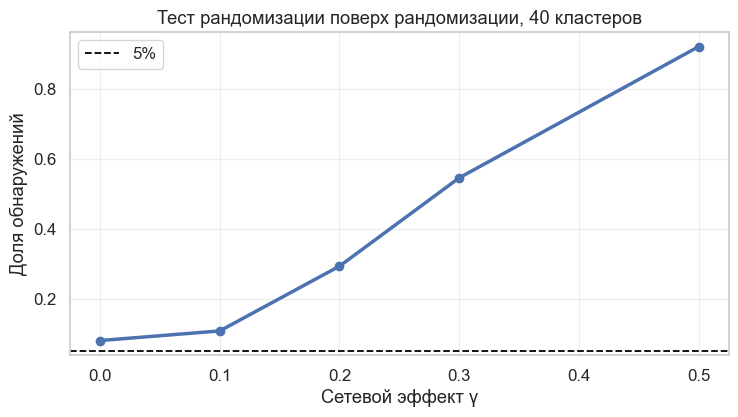

,Средняя разница,Доля отклонений H0
gamma,,
0.0,0.004,0.080
0.1,0.076,0.108
0.2,0.149,0.292
0.3,0.222,0.545
0.5,0.368,0.920


In [21]:
base_labels = partition_labels(3)
block_noise = np.random.default_rng(20).normal(0, np.sqrt(0.02), block.max() + 1)[block]
k_base = base_labels.max() + 1


def linkedin_test(gamma, tau=0.1, reps=400, seed=12):
    """Сравнивает индивидуальную и кластерную руку и возвращает разницу и долю отклонений H0."""
    local = np.random.default_rng(seed)
    n = len(base_labels)
    gaps, rejected = [], []
    for _ in range(reps):
        order = local.permutation(k_base)
        cluster_arm = np.zeros(k_base, bool)
        cluster_arm[order[:k_base // 2]] = True
        in_cluster_arm = cluster_arm[base_labels]
        z = local.random(n) < 0.5
        members = np.flatnonzero(cluster_arm)
        z[in_cluster_arm] = False
        chosen = local.permutation(members)[:len(members) // 2]
        z |= np.isin(base_labels, chosen)
        z = z.astype(float)
        y = tau * z + gamma * (adjacency @ z / np.maximum(degree, 1)) + block_noise + local.normal(0, 1, n)

        individual = ~in_cluster_arm
        mu_cr = y[individual & (z == 1)].mean() - y[individual & (z == 0)].mean()
        var_cr = y[individual & (z == 1)].var() / (individual & (z == 1)).sum() + y[individual & (z == 0)].var() / (individual & (z == 0)).sum()

        table = pd.DataFrame({'c': base_labels[in_cluster_arm], 'y': y[in_cluster_arm], 'z': z[in_cluster_arm]}).groupby('c').agg(s=('y', 'sum'), n=('y', 'size'), z=('z', 'first'))
        s, m, arm = table['s'].to_numpy(), table['n'].to_numpy(float), table['z'].to_numpy() == 1
        r1, r0 = s[arm].sum() / m[arm].sum(), s[~arm].sum() / m[~arm].sum()
        var_cbr = ((s[arm] - r1 * m[arm]) ** 2).sum() / m[arm].sum() ** 2 + ((s[~arm] - r0 * m[~arm]) ** 2).sum() / m[~arm].sum() ** 2
        gaps.append(r1 - r0 - mu_cr)
        clusters_in_arm = len(m)
        var_cbr *= clusters_in_arm / (clusters_in_arm - 1)
        rejected.append(abs(gaps[-1]) / np.sqrt(var_cr + var_cbr) > st.t.ppf(0.975, clusters_in_arm - 2))
    return np.mean(gaps), np.mean(rejected)


gammas = [0, 0.1, 0.2, 0.3, 0.5]
linkedin = pd.DataFrame([dict(zip(['Средняя разница', 'Доля отклонений H0'], linkedin_test(gamma)), gamma=gamma) for gamma in gammas]).set_index('gamma')

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(linkedin.index, linkedin['Доля отклонений H0'], 'o-', color=BLUE, lw=2.5)
ax.axhline(0.05, color='black', ls='--', lw=1.3, label='5%')
ax.set_xlabel('Сетевой эффект γ')
ax.set_ylabel('Доля обнаружений')
ax.set_title(f'Тест рандомизации поверх рандомизации, {k_base} кластеров')
ax.legend()
plt.show()
linkedin.round(3)

In [22]:
def two_stage(gamma, tau=0.1, low=0.2, high=0.8, reps=500, seed=13):
    """Оценивает эффекты двухэтапной рандомизации, усредняя по симуляциям."""
    local = np.random.default_rng(seed)
    n = len(base_labels)
    rows = []
    for _ in range(reps):
        share_cluster = local.permutation(np.where(np.arange(k_base) < k_base // 2, low, high))
        alpha = share_cluster[base_labels]
        z = (local.random(n) < alpha).astype(float)
        y = tau * z + gamma * (adjacency @ z / np.maximum(degree, 1)) + block_noise + local.normal(0, 1, n)
        y11, y10 = y[(z == 1) & (alpha == high)].mean(), y[(z == 1) & (alpha == low)].mean()
        y01, y00 = y[(z == 0) & (alpha == high)].mean(), y[(z == 0) & (alpha == low)].mean()
        rows.append({'Прямой при высокой доле': y11 - y01, 'Прямой при низкой доле': y10 - y00,
                     'Косвенный на контрольных': y01 - y00, 'Полный': y11 - y00})
    table = pd.DataFrame(rows)
    table['Оценка глобального эффекта'] = table['Прямой при низкой доле'] + table['Косвенный на контрольных'] / (high - low)
    return table


stages = two_stage(0.3)
summary = stages.agg(['mean', 'std']).T.rename(columns={'mean': 'Оценка', 'std': 'SD'})
print('Истина: прямой 0.10, сетевой эффект 0.30, глобальный 0.40')
summary.round(3)

Истина: прямой 0.10, сетевой эффект 0.30, глобальный 0.40


,Оценка,SD
Прямой при высокой доле,0.101,0.076
Прямой при низкой доле,0.104,0.074
Косвенный на контрольных,0.133,0.091
Полный,0.234,0.068
Оценка глобального эффекта,0.325,0.179


**Тест LinkedIn.** При $\gamma = 0$ доля отклонений 8%, немного выше 5%: в каждой руке только 20 кластеров, и это та же проблема малого числа кластеров. При $\gamma = 0.5$ тест находит эффект в 92% случаев, а при $\gamma = 0.1$ только в 11%. Поэтому незначимый результат не доказывает отсутствие интерференции. Вспомните, что LinkedIn в первом эксперименте тоже не отверг гипотезу.

**Двухэтапный дизайн.** Прямой эффект оценён верно: 0.10. Полный эффект 0.234 равен сумме прямого при высокой доле (0.101) и косвенного (0.133). Оценка глобального эффекта равна 0.325 при настоящих 0.40, и это не случайность. Дизайн предполагает частичную интерференцию, то есть что связи внутри кластера, а здесь чистота 74%. Поэтому видна примерно такая часть сетевого эффекта: $0.1 + 0.3 \cdot 0.75 = 0.325$. Заодно видно, что SD оценки 0.18 велика: чтобы разделить эффекты, нужно много кластеров.

## Сценарий: геоэксперименты

В геоэксперименте кластер — это регион: город, область, почтовый индекс. Подход используют, когда нельзя таргетировать пользователя: офлайн-продажи, ТВ, наружная реклама, цены, доставка. Классическая работа — [Вавер и Кёлер (2011)](https://research.google/pubs/measuring-ad-effectiveness-using-geo-experiments/) из Google.

Отличия от других сценариев:

* **регионов мало**: в США это 210 зон DMA, а в других странах обычно десятки единиц, причём пригодных для теста ещё меньше;
* **они очень разные**: крупнейший город может быть больше десятка малых вместе;
* **есть длинная история**: метрику региона мы видим за месяцы до теста, и это главный ресурс снижения дисперсии;
* **воздействие протекает через границы**: люди ездят и заказывают из соседнего региона.

### Дизайн и оценка

Обычно есть **период до теста** и **период теста**. Модель геоэксперимента (Geo-Based Regression, GBR):

$$
y_{i,1} = \beta_0 + \beta_1 y_{i,0} + \beta_2 \delta_i + \epsilon_i
$$

где $y_{i,0}$ и $y_{i,1}$ — метрика региона до и во время теста, а $\delta_i$ — величина воздействия в регионе. В рекламе это разница в затратах, и тогда $\beta_2$ равно окупаемости. Важно, что $\delta_i$ масштабируется с регионом: ниже мы берём $\delta_i = T_i y_{i,0}$, и $\beta_2 / \beta_1$ даёт относительный эффект. Веса берут обратно пропорциональными размеру региона $1/y_{i,0}$. По сути это ANCOVA и CUPED на уровне регионов. Вавер и Кёлер отмечают, что грамотное формирование групп до назначения может сузить интервал на 10% и больше, а дисперсию можно оценить заранее, разрезая историю на псевдопериоды.

Когда регионов совсем мало, например один тестовый город, используют временные ряды:

* **Time-Based Regression (TBR)** [Google](https://research.google/pubs/estimating-ad-effectiveness-using-geo-experiments-in-a-time-based-regression-framework/): предсказывает контрфактический ряд теста по контрольным регионам;
* **Синтетический контроль** из лекции 2.09 и его расширение **GeoLift** от [Meta](https://rdrr.io/github/facebookincubator/GeoLift/f/website/docs/Methodology/Methodology.md): подбирает веса контрольных рынков и проводит анализ мощности для разных наборов регионов;
* **Trimmed Match** от [Google](https://pdf.arxiv.org/pdf/2105.07060): парный дизайн с отбрасыванием пар, которые плохо сравнимы. Он нужен, потому что распределение регионов имеет тяжёлые хвосты.

Смоделируем 60 регионов с тяжёлым хвостом размеров: год недельной истории и 6 недель теста. Сравним четыре подхода по MDE относительного эффекта.

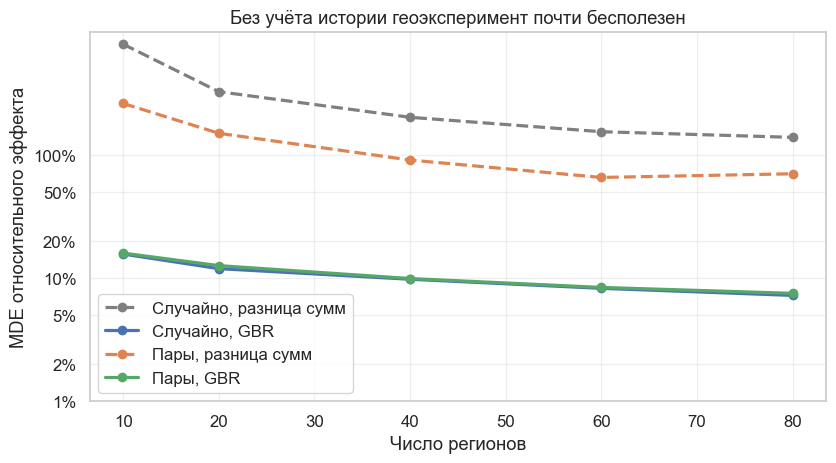

,"Случайно, разница сумм","Случайно, GBR","Пары, разница сумм","Пары, GBR"
10,801.1,15.7,263.9,16.0
20,329.2,12.0,151.1,12.7
40,203.8,9.8,91.6,10.0
60,155.6,8.3,66.1,8.4
80,140.1,7.3,70.8,7.5


In [23]:
def geo_panel(regions, local, weeks=58):
    """Генерирует продажи регионов по неделям: общий сезон, индивидуальные тренды и шум."""
    size = np.sort(np.exp(local.normal(0, 1.3, regions)))[::-1] * 1000
    time = np.arange(weeks)
    season = 1 + 0.12 * np.sin(2 * np.pi * time / 52) + 0.0015 * time
    loading = local.normal(1, 0.25, regions)
    trend = local.normal(0, 0.001, regions)
    shock = local.normal(0, 0.03, weeks)
    drift = np.zeros((weeks, regions))
    for week in range(1, weeks):
        drift[week] = 0.92 * drift[week - 1] + local.normal(0, 0.025, regions)
    level = np.outer(season, np.ones(regions)) + np.outer(shock, loading) + np.outer(time, trend) + drift
    noise = local.normal(0, 1, (weeks, regions)) * (0.05 + 0.6 / np.sqrt(size))
    return size * level * (1 + noise)


def gbr_lift(pre, post, arm):
    """Оценивает относительный эффект регрессией y1 на y0 и δ = T * y0 с весами 1/y0."""
    design = np.column_stack([np.ones(len(pre)), pre, arm * pre])
    root = np.sqrt(1 / pre)
    beta = np.linalg.lstsq(design * root[:, None], post * root, rcond=None)[0]
    return beta[2] / beta[1]


def geo_lifts(regions, reps=1500, pre_weeks=52, seed=14):
    """Считает разброс оценок эффекта при нулевом воздействии для разных подходов."""
    local = np.random.default_rng(seed)
    result = {name: [] for name in ['Случайно, разница сумм', 'Случайно, GBR', 'Пары, разница сумм', 'Пары, GBR']}
    for _ in range(reps):
        panel = geo_panel(regions, local)
        pre, post = panel[:pre_weeks].sum(axis=0), panel[pre_weeks:].sum(axis=0)
        random_arm = local.permutation(np.arange(regions) < regions // 2)
        order = np.argsort(-pre)[:regions - regions % 2]
        flip = local.random(regions // 2) < 0.5
        pair_arm = np.zeros(regions, bool)
        pair_arm[order[np.arange(0, len(order), 2) + flip]] = True
        for label, arm in [('Случайно', random_arm), ('Пары', pair_arm)]:
            control = ~arm
            result[f'{label}, разница сумм'].append((post[arm].sum() - post[control].sum()) / post[control].sum())
            result[f'{label}, GBR'].append(gbr_lift(pre, post, arm))
    return {name: 2.8 * np.std(values) for name, values in result.items()}


region_counts = [10, 20, 40, 60, 80]
geo_mde = pd.DataFrame({regions: geo_lifts(regions) for regions in region_counts}).T

fig, ax = plt.subplots(figsize=(9.5, 4.8))
for column, color, style in zip(geo_mde.columns, [GRAY, BLUE, ORANGE, GREEN], ['--', '-', '--', '-']):
    ax.plot(geo_mde.index, geo_mde[column] * 100, 'o', ls=style, color=color, lw=2.3, label=column)
ax.set_yscale('log')
ax.set_yticks([1, 2, 5, 10, 20, 50, 100], ['1%', '2%', '5%', '10%', '20%', '50%', '100%'])
ax.set_xlabel('Число регионов')
ax.set_ylabel('MDE относительного эффекта')
ax.set_title('Без учёта истории геоэксперимент почти бесполезен')
ax.legend()
plt.show()
(geo_mde * 100).round(1)

Без учёта истории результат бессмыслен: при 40 регионах MDE 204%. Суммы по группам определяются тем, куда попали самые крупные регионы, а пары по размеру только вдвое улучшают ситуацию. Регрессия на историю снижает MDE до 10%. При этом пары по размеру поверх регрессии уже не добавляют точности: вся информация о размере и так учтена.

Дальше MDE падает медленно: 10% при 40 регионах и 7.3% при 80. Шум определяется в основном крупными регионами, и новые мелкие мало что дают. Модель здесь иллюстративная, но порядок величин совпадает с практикой: у Avito в региональном тесте MDE выручки 8.5%, хотя условия и метрики другие.

Посмотрим на тест подробнее. Берём 40 регионов и пары, в тест идёт половина, настоящий эффект +5% за 6 недель. График показывает один запуск, а оценка в заголовке усреднена по 300 запускам. Контрфакт строим по TBR: обучаем связь суммы тестовых регионов с суммой контрольных на истории и прогнозируем период теста. Подвигайте эффект, а вторым параметром задайте утечку: часть эффекта, которая перетекает в контрольные регионы через границы.

In [24]:
def geo_case(effect, leak, regions=40, pre_weeks=52, seed=15):
    """Строит один геоэксперимент и контрфакт по контрольным регионам."""
    local = np.random.default_rng(seed)
    panel = geo_panel(regions, local)
    order = np.argsort(-panel[:pre_weeks].sum(axis=0))
    flip = local.random(regions // 2) < 0.5
    arm = np.zeros(regions, bool)
    arm[order[np.arange(0, regions, 2) + flip]] = True
    panel = panel.copy()
    panel[pre_weeks:, arm] *= 1 + effect
    panel[pre_weeks:, ~arm] *= 1 + effect * leak
    test, control = panel[:, arm].sum(axis=1), panel[:, ~arm].sum(axis=1)
    slope, intercept = np.polyfit(control[:pre_weeks], test[:pre_weeks], 1)
    counterfactual = intercept + slope * control
    return test, counterfactual, test[pre_weeks:].sum() / counterfactual[pre_weeks:].sum() - 1


def plot_geo_case(ax, effect, leak, runs=300):
    test, counterfactual, _ = geo_case(effect, leak)
    lifts = np.array([geo_case(effect, leak, seed=run)[2] for run in range(100, 100 + runs)])
    weeks = np.arange(len(test))
    ax.plot(weeks[30:], test[30:] / 1000, color=BLUE, lw=2.2, label='Тестовые регионы')
    ax.plot(weeks[30:], counterfactual[30:] / 1000, color=RED, lw=2.2, label='Контрфакт')
    ax.axvline(51.5, color=GRAY, ls=':', lw=2)
    ax.set_title(f'Эффект {effect:.0%}, утечка {leak:.0%}: средняя оценка {lifts.mean():.1%}, SD {lifts.std():.1%}', fontsize=12)
    ax.set_xlabel('Неделя')
    ax.set_ylabel('Продажи, тыс.')
    ax.legend(fontsize=10)


def geo_demo(effect=0.05, leak=0.0):
    fig, ax = plt.subplots(figsize=(9, 4.3))
    plot_geo_case(ax, effect, leak)
    plt.show()


interact(geo_demo,
         effect=FloatSlider(value=0.05, min=0, max=0.2, step=0.01, description='Эффект'),
         leak=FloatSlider(value=0, min=0, max=0.6, step=0.05, description='Утечка'));

Статичная версия: без утечки и с утечкой 30%.

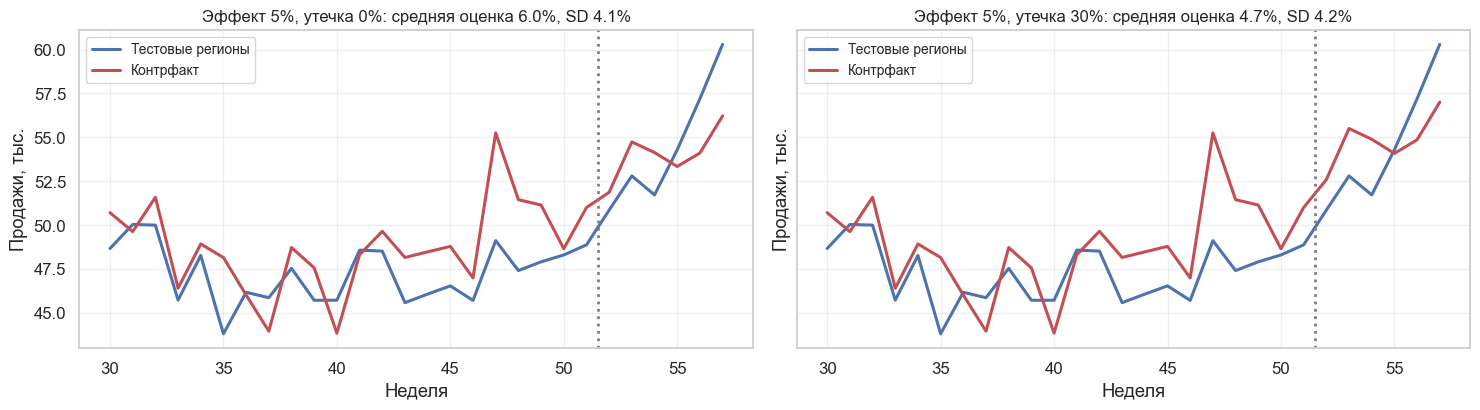

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), sharey=True)
for ax, leak in zip(axes, [0, 0.3]):
    plot_geo_case(ax, 0.05, leak)
plt.tight_layout()

Без утечки средняя оценка равна 6.0% при настоящих 5%, а SD 4.1%. Завышение на 1 п.п. — свойство такого простого TBR: шум в контрольном ряду занижает наклон, и контрфакт немного отстаёт от роста. Поэтому метод надо проверять на искусственном эффекте. Утечка 30% снижает оценку до 4.7%: контрольные регионы тоже выросли, и разница уменьшилась. Если подозреваете утечку, оставляйте между тестом и контролем буферные регионы или выбирайте изолированные рынки.

### Проверка: плацебо по датам

У геотеста одна реализация назначений, поэтому важна проверка на истории. Сдвигаем период теста в прошлое и считаем «эффект», которого не было. Разброс таких оценок показывает реальный шум метода и заодно подсказывает MDE ещё до запуска. Вавер и Кёлер используют ту же идею псевдопериодов.

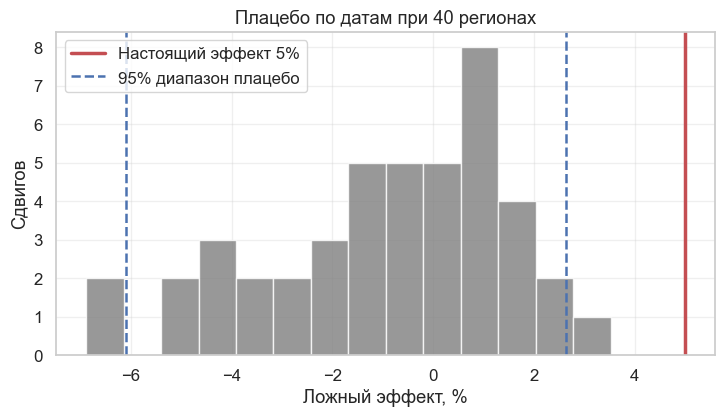

Плацебо: среднее -0.90%, SD 2.40%, MDE примерно 6.7%


In [26]:
def date_placebo(regions=40, seed=16, weeks_test=6, train=26):
    """Сдвигает период теста по истории и считает ложный эффект TBR."""
    local = np.random.default_rng(seed)
    panel = geo_panel(regions, local, weeks=120)
    order = np.argsort(-panel[:train].sum(axis=0))
    flip = local.random(regions // 2) < 0.5
    arm = np.zeros(regions, bool)
    arm[order[np.arange(0, regions, 2) + flip]] = True
    test, control = panel[:, arm].sum(axis=1), panel[:, ~arm].sum(axis=1)
    lifts = []
    for start in range(train, len(test) - weeks_test, 2):
        slope, intercept = np.polyfit(control[start - train:start], test[start - train:start], 1)
        lifts.append(test[start:start + weeks_test].sum() / (intercept + slope * control[start:start + weeks_test]).sum() - 1)
    return np.array(lifts)


placebo = date_placebo()
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(placebo * 100, bins=14, color=GRAY, alpha=0.8)
ax.axvline(5, color=RED, lw=2.5, label='Настоящий эффект 5%')
ax.axvline(np.percentile(placebo * 100, 2.5), color=BLUE, ls='--', lw=1.8, label='95% диапазон плацебо')
ax.axvline(np.percentile(placebo * 100, 97.5), color=BLUE, ls='--', lw=1.8)
ax.set_xlabel('Ложный эффект, %')
ax.set_ylabel('Сдвигов')
ax.set_title('Плацебо по датам при 40 регионах')
ax.legend()
plt.show()
print(f'Плацебо: среднее {placebo.mean():.2%}, SD {placebo.std():.2%}, MDE примерно {2.8 * placebo.std():.1%}')

SD плацебо равна 2.4%, что даёт MDE около 6.7% для этого разбиения. Это согласуется с симуляцией выше. Настоящий эффект 5% лежит за пределами 95% диапазона плацебо, но запас невелик: для одного конкретного разбиения разница заметна, а обнаружить её стабильно будет трудно. Заметьте и среднее -0.9%: разбиение не идеально, и остаётся небольшой сдвиг.

### Кейс Avito

В [статье об оценке ранжирования](https://habr.com/ru/companies/avito/articles/1043880/) Avito сравнивает способы измерить влияние изменения поиска на выручку.

| Сетап | Что видно | Проблема |
| :--- | :--- | :--- |
| A/B по покупателям | Поведение покупателей, очень чувствителен | Не видно изменений поведения продавцов |
| A/B по продавцам | Поведение продавцов | Сетевой эффект: рост 88% при настоящих 36% |
| Кластерный тест по регионам | И продавцы, и покупатели, сетевого эффекта почти нет | Кластеров очень мало, MDE выручки 8.5% |
| Интерливинг (см. 2.06) | Сетевого эффекта между группами почти нет | Не видно долгосрочного поведения, MDE выручки 2.5% |

Авторы делят регионы на тест и контроль, и эффект считают как разницу выручки на продавца. Они отмечают две проблемы, которые мы разобрали: мало кластеров и сложный подбор. Число регионов и способ подбора в статье не раскрыты.

[Другая статья Avito](https://habr.com/ru/companies/avito/articles/929894/) показывает, что иногда лучше уйти от регионов. Для теста на недобросовестных продавцах вместо регионального теста сделали разбиение продавцов и покупателей с управляемой силой воздействия: покупатели делятся 10/80/10, а эффект пересчитывается через измеренную утечку трафика $A$ по силе воздействия $0.8(1 + A)$. Это снизило MDE выручки с 8% до 4%. Идея близка к разделу о проверке интерференции: сначала измеряем сетевой эффект, а затем поправляем на него. Поправка предполагает, что выручка линейна по силе воздействия.

## Кейсы компаний

| Компания | Единица | Масштаб | Что показали |
| :--- | :--- | :--- | :--- |
| [Meta](https://ar5iv.labs.arxiv.org/html/2012.08591) | Сообщества графа, зоны поездок на работу | Граф из 2 млрд вершин, до $10^6$ кластеров | Пользовательская оценка завышена: 71.8% ± 5.1% против 49.7% ± 17.8% у кластерной |
| [LinkedIn](https://faculty.washington.edu/msaveski/assets/publications/2017_detecting_network_effects/paper.pdf) | Сбалансированные кластеры | 1 000–10 000 кластеров | Сетевые эффекты выявлены в одном из двух экспериментов |
| [Airbnb](https://business.columbia.edu/faculty/research/reducing-interference-bias-online-marketplace-experiments-using-cluster) | Кластеры объявлений | Мета-эксперимент | Минимум 20% индивидуальной оценки — смещение |
| [Avito](https://habr.com/ru/companies/avito/articles/1043880/) | Регионы | Точное число не раскрыто | MDE выручки 8.5% |
| [Avito](https://habr.com/ru/companies/avito/articles/1040162/) | Специалисты поддержки | 20–150 на группу | Подбор групп, CUPED снизил ошибку примерно на 36% |
| [X5](https://habr.com/ru/companies/X5Tech/articles/466349/) | Магазины | Сеть из 15 000 магазинов | Подбор пар по истории, A/A и искусственный эффект: для 1% нужно 421 магазино-день |
| [Google](https://research.google/pubs/measuring-ad-effectiveness-using-geo-experiments/) | Регионы | До 210 DMA | ANCOVA на регионах и анализ мощности по истории |

## Чек-лист запуска

**До теста**

1. Определите причину кластеризации и какой уровень реально разрывает зависимость.
2. Определите оцениваемую величину: эффект на пользователя, на кластер или глобальный эффект.
3. Оцените ICC и эффект дизайна на истории, посчитайте MDE по числу кластеров.
4. Выберите схему рандомизации: стратификацию или пары, где это возможно.
5. Зафиксируйте метод анализа и проверьте его на A/A и искусственном эффекте.

**Во время теста**

6. Следите за утечками: перемещения между кластерами, изменение состава.
7. Состав кластера определяйте заранее. Если воздействие меняет то, кто попадает в кластер, возникает смещение отбора.

**Анализ**

8. Анализируйте на уровне назначения и учитывайте схему: пары, страты, подбор.
9. При малом числе кластеров используйте рандомизационный вывод, wild bootstrap или агрегацию.
10. Используйте метрику до теста. Для геотестов это почти обязательно.
11. Проверьте остаточную интерференцию, если есть основания.

## Типичные ошибки

* Назначить кластерам, а считать t-тест по пользователям.
* Планировать мощность по числу пользователей.
* Считать кластером то, что удобно, а не то, что разрывает зависимость.
* Оптимизировать разбиение на результат самого теста.
* Подбирать группы, а анализировать как при простой рандомизации.
* Смотреть на A/A только по ошибке первого рода: занижение тоже сигнал о несоответствии.
* Считать, что кластеры устранили всю интерференцию.

## Заключение

| Сценарий | Единица | Главная проблема | Что помогает |
| :--- | :--- | :--- | :--- |
| Готовые группы | Школа, магазин | Мало кластеров, ICC | Пары, метрика до теста, A/A |
| Интерференция | Сообщество на графе | Компромисс чистоты и дисперсии | Разбиение графа, проверка остаточного эффекта |
| Гео | Регион | Мало и очень разные | История, пары, TBR, синтетический контроль |

Главное из лекции:

* кластеризация решает проблему смещения и платит дисперсией: $DE = 1 + (m-1)\rho$;
* мощность определяет прежде всего число кластеров, а наращивание пользователей внутри упирается в предел;
* единица анализа должна соответствовать единице назначения, а метод — схеме рандомизации;
* при малом числе кластеров обычные CRSE занижают дисперсию, и нужны рандомизационный вывод или wild bootstrap;
* чистота кластеров на реальном графе далека от 100%, поэтому остаточную интерференцию надо проверять;
* в геоэкспериментах главный ресурс — история метрики, а самая честная оценка шума — плацебо по датам.